---
title: "Van Krevelen-Hoftijzer: the chart replaced by a solve, and the assumption behind it measured"
description: "The enhancement factor for a second-order gas-liquid reaction is an implicit relation that textbooks hand over as a chart. Solving the film equations instead prices the approximation everywhere on that chart, tests the assumption stated for it in both of the wordings Froment, De Wilde and Bischoff print, and shows that one of Levenspiel's printed expansions expands the approximation rather than the equations it approximates."
categories: [sec:F, struct:S3, tier:T0, data:tier6, phase:gas-liquid]
date: 2026-08-14
---

# Van Krevelen-Hoftijzer: the chart replaced by a solve, and the assumption behind it measured

**Catalog ID:** `F3.2` · **Structures:** `S3` (1-D steady BVP) · **Tier:** T0

The two film equations of a second-order gas-liquid reaction are solved with
pymrm and the Van Krevelen-Hoftijzer enhancement factor is priced against
them over the whole printed chart, together with the assumption it is said to
rest on and Levenspiel's three printed expansions of it.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.28.4"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F3.2-van-krevelen-hoftijzer"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. Nothing beyond pymrm and the Colab defaults is needed.
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gallery_utils import Claims, cite_data, load_claims, load_data, load_meta
from pymrm.checks import observed_orders
from model import (Extrapolated, Film, f_a_bvp, f_a_vkh, f_a_vkh_route_b,
                   argext_log, graded_film, root_log, unique_root_log)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5, "axes.grid": True,
                     "grid.alpha": 0.25})
# Okabe-Ito, assigned in fixed order and never cycled
C_BLUE, C_ORANGE, C_GREEN = "#0072B2", "#D55E00", "#009E73"
C_PURPLE, C_YELLOW, C_GREY = "#CC79A7", "#E69F00", "0.45"
np.set_printoptions(precision=8, suppress=False)
# Nothing on this page is stochastic, and every film solve is a cold start from
# a closed-form profile that depends only on its own (gamma, q).
claims = Claims(PAGE.split("-")[0])

## Background

A gas $A$ dissolving into a liquid that holds a reactant $B$ is absorbed faster
than it would be by dissolution alone. The ratio is the **enhancement factor**,
and for a genuinely second-order reaction it has no closed form: the two film
equations are coupled and nonlinear, and every design chart in the field
descends from one approximate solution of them.

That approximation is **Van Krevelen and Hoftijzer's (1948)**. This page does
two things with it that a chart cannot: it *solves* the implicit relation
instead of reading it off, and it *measures the assumption* the approximation
is built on.

### The source situation, stated plainly

**The 1948 origin was not consulted.** Van Krevelen, D. W. and Hoftijzer,
P. J., *Kinetics of gas-liquid reactions. Part I. General theory*, Recueil des
Travaux Chimiques des Pays-Bas **67**, 563 (1948), is not on disk and was not
read. Every equation on this page is transcribed from a monograph that
restates it with attribution, and the transcription is named equation by
equation below.

**The text read is Froment, De Wilde and Bischoff.** *Chemical Reactor
Analysis and Design*, 3rd edition, John Wiley & Sons (2011), ISBN
978-0-470-56541-4, Chapter 6 *Gas-Liquid Reactions*. It qualifies as a source
for a page *about this result* rather than merely a book that mentions it:
section 6.3.2 (book p. 331) says the diagram is "as first given by Van Krevelen
and Hoftijzer [1948]"; section 6.3.3 (book p. 335) says the intermediate curves
"were calculated by Van Krevelen and Hoftijzer [1948] under the assumption that
B is only weakly depleted near the interface"; and section 6.3.5 (book p. 340)
derives the approximation itself and prints its accuracy claim. Named,
attributed, derived, and its assumption stated.

**Levenspiel is a cross-check, not a second source.** *Chemical Reaction
Engineering*, 3rd edition, John Wiley & Sons (1999), Chapter 23, carries the
same result as a chart in a different notation with three asymptotic
expansions printed in its annotation boxes. Those expansions are used here to
check Froment's constants independently and to reconcile the two notations.
Nothing on this page adjudicates between the books.

### Every equation was read on a render, and here is why that matters

The Froment file is born-digital and its prose extracts cleanly, **but its
equations do not survive extraction and the failure is silent**. Every
Symbol-font operator becomes an unmappable Private-Use-Area glyph - `U+F02D`
for minus, `U+F03D` for equals, `U+F02B` for plus - which renders as nothing.
The extraction of the central equation of this page, (6.3.5-1), reads exactly

```
  '    1   FA   1

b D A C Ai
a DB C Bb
```

Seven characters have gone: `U+F067` (the leading $\gamma$), `U+F03D` (the
equals), `U+F067` again, `U+F02D` (a minus), `U+F028` (an opening bracket),
`U+F02D` (the second minus) and `U+F029`. The square root sign has no character
at all - it is drawn, not typeset - and the fraction bar is a line. What is left
looks like a complete equation and contains no operator whatsoever. Every
equation and every numeral used here was read on a 300 ppi render (Levenspiel:
600 ppi, his file's native resolution), cropped and enlarged.


## The published model

### The film equations (Froment, section 6.3.1)

A stagnant liquid film of thickness $y_L$ at the interface, everything beyond
it well mixed, and an irreversible reaction $aA + bB \rightarrow$ products.
With $\xi = y/y_L$, $\alpha = C_A/C_{Ai}$ and $\beta = C_B/C_{Bb}$,

$$
\frac{\mathrm{d}^2\alpha}{\mathrm{d}\xi^2} = \gamma^2\,\alpha\beta,
\qquad
\frac{\mathrm{d}^2\beta}{\mathrm{d}\xi^2} = \frac{\gamma^2}{q}\,\alpha\beta ,
$$

$$
\gamma = \frac{\sqrt{k D_A}}{k_L},
\qquad
q = \frac{a\,D_B\,C_{Bb}}{b\,D_A\,C_{Ai}} ,
$$

with $\alpha(0) = 1$ (saturated interface), $\alpha(1) = 0$ - Van Krevelen and
Hoftijzer "could set $C_{Ab} = 0$", book p. 340 - $\beta'(0) = 0$ ($B$ is
non-volatile) and $\beta(1) = 1$. The enhancement factor is the interfacial
flux divided by the purely diffusive one,

$$
F_A = \frac{N_A}{k_L (C_{Ai} - C_{Ab})}
= -\left.\frac{\mathrm{d}\alpha}{\mathrm{d}\xi}\right|_{\xi = 0} .
$$

$\gamma$ is Froment's symbol and his eq. (6.3.2-1) *et seq.*; he notes it "is
sometimes called the Hatta number" (book p. 328). $q$ is the group his
Fig. 6.3.2-1 carries as its right-hand axis title, and his eq. (6.3.3-10) makes
the instantaneous ceiling $F_A = 1 + q$.

### The approximation this page is about

**Pseudo-first-order**, exact when $\beta \equiv 1$ - Froment (6.3.2-11):

$$
F_A = \frac{\gamma}{\tanh\gamma}
$$

**Van Krevelen-Hoftijzer**, "entirely analogous with that obtained for a
pseudo-first-order reaction (6.3.2-11), but with $\gamma$ replaced by
$\gamma'$" - Froment (6.3.5-1), book p. 340, read on a 300 ppi crop enlarged
2x:

$$
\gamma' = \gamma\sqrt{1 - (F_A - 1)\,\frac{b\,D_A\,C_{Ai}}{a\,D_B\,C_{Bb}}}
\;=\; \gamma\sqrt{1 - \frac{F_A - 1}{q}} ,
\qquad
F_A = \frac{\gamma'}{\tanh\gamma'} .
$$

$F_A$ appears on both sides: this is the implicit relation, and solving it is
what the chart exists to avoid. The sentence that follows it in the book is the
claim this page measures: *"This approximate solution is valid to within 10
percent of the numerical solution."*

And the sentence three sections earlier, book p. 335, is the assumption this
page tests: the intermediate curves *"were calculated by Van Krevelen and
Hoftijzer [1948] under the assumption that B is only weakly depleted near the
interface. For moderately fast reactions, this assumption was reasonably
confirmed by more rigorous computations."*

### The same result in Levenspiel's notation

| Froment | Levenspiel | this page |
|---|---|---|
| $\gamma = \sqrt{kD_A}/k_L$ | $M_H = \sqrt{\mathcal{D}_A k C_B}/k_{Al}$ | `gamma` |
| $F_A$ | $E$ | `f_a` |
| $q = aD_BC_{Bb}/(bD_AC_{Ai})$ | $E_i - 1$, from $E_i = 1 + \mathcal{D}_BC_BH_A/(b\mathcal{D}_Ap_{Ai})$ | `q` |
| $F_A \to 1 + q$ | $E \to E_i$ | the plateau |

The two groups are the same objects written differently - $p_{Ai} = C_{Ai}/H_A$
turns Levenspiel's $E_i$ into Froment's $1 + q$ - **but the curve labels on the
two charts are not.** Froment's Fig. 6.3.2-1 labels its curves with $q$;
Levenspiel's Fig. 23.4 labels the same family with $E_i$. Both print the same
ten numerals. A curve labelled 1 plateaus at $F_A = 2$ in one book and at
$E = 1$ in the other, and the page computes what that costs.

Levenspiel's Fig. 23.4 also prints three asymptotic expansions in its
annotation boxes, and every constant in them is checked here against the
implicit relation above and against the film equations themselves:

$$
E \cong 1 + \frac{M_H^2}{3} + \dots
\qquad
E = M_H\left(1 - \frac{M_H - 1}{2E_i}\right) + \dots
\qquad
E \cong E_i - \frac{E_i^2(E_i-1)}{M_H^2} + \dots
$$


## Parameters and assumptions

**Assumptions**, all of them the source's: steady state; a stagnant film with
no surface renewal; irreversible second-order kinetics, first order in each
reactant; constant diffusivities; $C_{Ab} = 0$, so no reaction in the bulk;
$B$ non-volatile. The problem is then dimensionless and has exactly two
parameters, $\gamma$ and $q$.

**Nothing here is fitted, and nothing here is measured.** Both sides of every
comparison on this page are equations: an approximation on one side and the
equations it approximates on the other. This is provenance tier 6. The page
therefore establishes nothing whatever about how well the film model describes
a real absorber - only how well one solution of it describes another.

**The search domain**, and each end taken from the row that actually carries
it. $\gamma \in [0.5, 1000]$ is Froment's own printed $\gamma$ axis,
transcribed. The $q$ range comes from the printed **curve labels** - $q$ is
what those labels are - so its upper end is the largest of them, and its lower
end goes one decade below the smallest, because $q$ is a physical ratio and not
a drawn curve. The two ends happen to coincide numerically with the $\gamma$
axis; they are looked up from different rows all the same. The worst point
turns out to lie in the interior of both, so widening the domain cannot move
it.

**Where this page stops, and what `F3.1` owns.** `F3.1` owns the Hatta number
and the regime map, and it already reports a maximum Van Krevelen-Hoftijzer
error over the three $E_i$ values it sweeps. That number is
loaded from `F3.1`'s own `agreement.json` in the Validation section, recomputed
under this page's definitions, and reconciled - not retyped. This page does not
restate the regime picture, and it does not touch DeCoursey, which is `F3.3`.


## The data

There is no experimental dataset here and there could not be: the case is an
approximation to a pair of differential equations. What the two CSVs carry is
**transcription** - the numbers and sentences the two books print around this
result - so that the notebook tests them instead of retyping them.

Both books were read on renders at their files' native resolutions, and the
page/PDF mapping is recorded in the sidecars so any reader can re-render
exactly what was read (Froment: book = PDF $-$ 42; Levenspiel: book = PDF
$-$ 16, both confirmed on printed running heads).

One caution about the figure, because it is the exact trap the house rule
exists for. The Froment file is born-digital and its equations
and prose are vector text at any resolution - **but its figure is not**.
`pdfimages -list` shows Fig. 6.3.2-1, on PDF p. 373, as an embedded
$536\times771$ greyscale JPEG at 148 ppi, so a 300 ppi page render is a 2x
interpolation of a 148 ppi raster. The raster was extracted and the ten curve
labels, the four axis ends and both axis titles read at native resolution
enlarged 4x.


In [3]:
PRN = load_data("vkh-printed-claims.csv", page=PAGE).set_index("claim_id")
PMETA = load_meta("vkh-printed-claims.csv", page=PAGE)
LAB = load_data("enhancement-chart-labels.csv", page=PAGE)
LMETA = load_meta("enhancement-chart-labels.csv", page=PAGE)


def printed(key, field="value"):
    """A printed constant, looked up - never retyped in a cell."""
    return float(PRN.loc[key, field])


def quoted(key):
    return str(PRN.loc[key, "verbatim"])


print(cite_data(PMETA))
print(f"{len(PRN)} transcribed rows, {len(LAB)} chart labels\n")
for k in ("froment_vkh_validity_pct", "froment_film_completion_gamma",
          "froment_bulk_reaction_gamma"):
    print(f'  {k:32s} {PRN.loc[k, "value"]:>8}   book p.{PRN.loc[k, "book_page"]}'
          f'  "{quoted(k)}"')
for k in ("lev_small_M_coeff", "lev_pfo_correction_denom", "lev_pfo_correction_offset",
          "lev_inst_correction_power", "lev_pfo_threshold", "lev_inst_threshold"):
    print(f'  {k:32s} {PRN.loc[k, "value"]:>8}   book p.{PRN.loc[k, "book_page"]}'
          f'  "{quoted(k)}"')

# ---- the domain of every search on this page, read off the printed axes -----
# gamma comes from the printed gamma AXIS; q comes from the printed curve
# LABELS, which is what q is drawn as - two different transcribed sources, and
# each is looked up from the row that actually carries it.
LABELS = [int(v) for v in LAB["label"]]
G_LO, G_HI = printed("froment_gamma_axis_lo"), printed("froment_gamma_axis_hi")
Q_HI = float(max(LABELS))
Q_LO = float(min(LABELS)) / 10.0   # one decade below the smallest printed label
print(f"\nsearch domain: gamma in [{G_LO:g}, {G_HI:g}] (Froment's printed gamma axis),"
      f"  q in [{Q_LO:g}, {Q_HI:g}]")
print(f"printed curve labels, both books: {LABELS}")
print(f"  q's range comes from those labels, not from the gamma axis: the largest"
      f" printed label is {max(LABELS):g}"
      f"\n  and the search goes one decade below the smallest, {min(LABELS):g}, because"
      f" q is a physical ratio")
print(f"  and not a drawn curve.  The worst point turns out to be interior in both"
      f" directions, so"
      f"\n  widening the domain cannot move it.")

Froment, G. F.; De Wilde, J.; Bischoff, K. B. (2011) — "Chemical Reactor Analysis and Design", 3rd edition, John Wiley & Sons (2011), ISBN 978-0-470-56541-4, Chapter 6 "Gas-Liquid Reactions", sections 6.3.2 (book pp. 328-332), 6.3.3 (book p. 335) and 6.3.5 (book pp. 340-341), reference list book p. 365
 — transcription
25 transcribed rows, 10 chart labels

  froment_vkh_validity_pct             10.0   book p.340  "This approximate solution is valid to within 10 percent of the numerical solution."
  froment_film_completion_gamma         3.0   book p.331  "The reaction is essentially completed in the film when gamma > 3"
  froment_bulk_reaction_gamma           0.3   book p.331  "whereas it takes place mainly in the bulk when gamma < 0.3"
  lev_small_M_coeff                     3.0   book p.530  "E = 1 + M_H^2/3 + ..."
  lev_pfo_correction_denom              2.0   book p.530  "More precisely  E = M_H(1 - (M_H - 1)/(2 E_i)) + ..."
  lev_pfo_correction_offset             1.0   book p.530  "

### One printed defect, reported and not repaired

Levenspiel spells the first author **"van Krevelens"**, with a terminal *s*, in
both places he names him. It is settled against another document rather than
against memory: Froment cites the same paper - same journal, same volume 67,
same page 563 - and spells it *Van Krevelen*.

This is a defect in the cross-check source, not in the E1.1 target, and it
changes nothing computed here. The two books' *citations* do not conflict:
Froment cites the 1948 *Rec. Trav. Chim.* paper, Levenspiel's chart caption
credits a 1954 *Trans. I. Chem. E.* paper, and Levenspiel's own reference list
carries **both**. Those are two publications, not a discrepancy. Neither is on
disk.


In [4]:
for k in ("froment_surname_in_text", "froment_surname_in_reflist",
          "levenspiel_surname_in_caption", "levenspiel_surname_in_reflist"):
    print(f'{PRN.loc[k, "source"]:11s} book p.{PRN.loc[k, "book_page"]:>4}  "{quoted(k)}"')

FROMENT_SPELLING = "Van Krevelen"
LEV_SPELLING = "van Krevelens"
SPELLING_DIFFERS = (FROMENT_SPELLING.lower() not in
                    [quoted("levenspiel_surname_in_caption").split()[i] + " " +
                     quoted("levenspiel_surname_in_caption").split()[i + 1]
                     for i in range(len(quoted("levenspiel_surname_in_caption").split()) - 1)])
IN_FROMENT = sum(FROMENT_SPELLING in quoted(k)
                 for k in ("froment_surname_in_text", "froment_surname_in_reflist"))
IN_LEV = sum(LEV_SPELLING in quoted(k)
             for k in ("levenspiel_surname_in_caption", "levenspiel_surname_in_reflist"))
SAME_PAPER = all(s in quoted("levenspiel_surname_in_reflist") for s in ("67", "563", "1948"))
print(f"\n'{FROMENT_SPELLING}' in {IN_FROMENT} of the 2 Froment rows;"
      f"  '{LEV_SPELLING}' in {IN_LEV} of the 2 Levenspiel rows.")
print(f"both reference lists carry volume 67, page 563, year 1948: {SAME_PAPER}")
if not (IN_FROMENT == 2 and IN_LEV == 2 and SAME_PAPER):
    raise ValueError("the transcribed citation rows no longer show one paper, two spellings")
print("-> one paper, two spellings.  This page uses the spelling without the s,"
      "\n   which is the one the E1.1 target and the catalogue use.")

froment     book p. 331  "as first given by Van Krevelen and Hoftijzer [1948]"
froment     book p. 365  "Van Krevelen, D.W., and Hoftijzer, P.J., Rec. Trav. Chim. Pays-Bas, 67, 563 (1948)."
levenspiel  book p. 530  "modified from the numerical solution of van Krevelens and Hoftijzer (1954)."
levenspiel  book p. 537  "van Krevelens, D. W., and Hoftijzer, P. J., Rec. Trav. Chim., 67, 563 (1948); Trans. I. Chem. E., 32, 5360 (1954)."

'Van Krevelen' in 2 of the 2 Froment rows;  'van Krevelens' in 2 of the 2 Levenspiel rows.
both reference lists carry volume 67, page 563, year 1948: True
-> one paper, two spellings.  This page uses the spelling without the s,
   which is the one the E1.1 target and the catalogue use.


## PyMRM implementation

Three solvers, and they are kept apart on purpose.

1. **The film equations, in pymrm.** Finite volumes on a slab (`nu=0`) with a
   graded grid clustered at the interface, per-species boundary conditions in
   one pair of `{"a","b","d"}` dictionaries, and `newton` + `NumJac` on the
   pointwise reaction term. This is the "numerical solution" Froment's accuracy
   claim is made against.
2. **The same equations by collocation.** `scipy.integrate.solve_bvp`, adaptive
   mesh, fourth order, sharing no assembly, no Jacobian and no mesh with (1).
   Every headline that depends on the film solution is computed both ways.
3. **The implicit relation**, solved twice: for $F_A$ by Brent, and again for
   $\gamma'$ with $F_A$ eliminated - a different unknown and a different
   residual for the same pair of printed equations.

Two details that are not decoration. The grid is **graded**: with
$x_f = (\mathrm{e}^{s t} - 1)/(\mathrm{e}^{s} - 1)$ and $s = 8$ the reaction
layer near $\xi = 0$ is resolved at $\gamma = 1000$, where a uniform grid of
the same size is not - `construct_grad` and `construct_div` take arbitrary face
positions, so this costs one line. And `NumJac` is given `(n_x, 2)` and never a
bare `(n_x,)`: the reaction term is pointwise in the two fields, which is
exactly the default stencil, while a bare 1-D shape would declare every cell
coupled to every other and build a dense Jacobian.

**The reference is not a single solve.** Grading is not free: it buys the
high-$\gamma$ end and it *costs* accuracy at moderate $\gamma$, which is
exactly where this page's headline sits, because the outer cells of a graded
grid are several times wider than a uniform one's. Both effects are measured
below. So the baseline every error here is quoted against is a **Richardson
extrapolation of the same graded film on $n_x = 400$ and $n_x = 800$**,
$F(2n) + [F(2n) - F(n)]/3$, which the observed order (Validation, check 4)
licenses. A single graded solve at $n_x = 800$ is *not* converged at the fourth
decimal of the headline; the break table's "reference taken as one graded
solve" row is that defect, and the extrapolated baseline is checked against
collocation and against a finer extrapolation in the Validation section.

The classes live in `model.py` next to this notebook. The boundary conditions,
with $n$ the outward normal ($-\xi$ at the interface, $+\xi$ at the bulk edge),
one column per field $(\alpha, \beta)$:

| face | $\alpha$ | $\beta$ |
|---|---|---|
| $\xi = 0$, interface | $\alpha = 1$ (saturated) | $-\mathrm{d}\beta/\mathrm{d}\xi = 0$ ($B$ non-volatile) |
| $\xi = 1$, bulk edge | $\alpha = 0$ ($C_{Ab} = 0$) | $\beta = 1$ (bulk value) |

The break table also uses a zero-gradient bulk edge for $\beta$,
$\mathrm{d}\beta/\mathrm{d}\xi = 0$ at $\xi = 1$, which cuts the supply of $B$.
$F_A$ is row 0 of the assembled face-flux operator, the flux through the
interface face that the solve transports, and $\beta(0)$ comes from
`compute_boundary_values`. `newton` keeps both fields non-negative with a lower
bound of 0 and raises unless it converges.

Every solve is a **cold start** from a closed-form profile that depends only on
its own $(\gamma, q)$, so no reported number depends on a neighbouring solve.


In [5]:
FILM = graded_film(800, 8.0)                 # the fine grid of the pair
FILM_C = graded_film(400, 8.0)               # its coarse partner
REF = Extrapolated(FILM_C, FILM)             # the baseline of this page
REF_FINE = Extrapolated(FILM, graded_film(1600, 8.0))   # only to check REF
print(f"film: n_x = {FILM.n_x}, grading s = {FILM.stretch:g},"
      f" first cell {FILM.x_f[1]:.3e} wide, last {1 - FILM.x_f[-2]:.3e}")
print(f"the reference is Richardson(n_x = {FILM_C.n_x}, {FILM.n_x}) on that grid,"
      f" order 2, not a single solve")
print(f"F_A at (gamma, q) = (10, 4):  pymrm n_x = 800 {FILM.f_a(10.0, 4.0)[0]:.8f}"
      f"   extrapolated {REF.f_a(10.0, 4.0)[0]:.8f}")
print(f"{'':29s}collocation {f_a_bvp(10.0, 4.0)[0]:.8f}"
      f"   VKH {f_a_vkh(10.0, 4.0):.8f}")

film: n_x = 800, grading s = 8, first cell 3.373e-06 wide, last 9.954e-03
the reference is Richardson(n_x = 400, 800) on that grid, order 2, not a single solve
F_A at (gamma, q) = (10, 4):  pymrm n_x = 800 4.36054570   extrapolated 4.36055397
                             collocation 4.36055397   VKH 4.27093555


## Results

### 1. The chart, computed

Froment's Fig. 6.3.2-1 and Levenspiel's Fig. 23.4 are the same picture: the
implicit relation, solved once and drawn as a family of curves so that nobody
has to solve it again. Here it is solved - the curves below are computed from
the equations at the ten labels both books print, and nothing is traced.

The plateau check is the point of the notation table above: at the *same*
printed label, Froment's curve levels off at $1 + q$ and Levenspiel's at $E_i$.


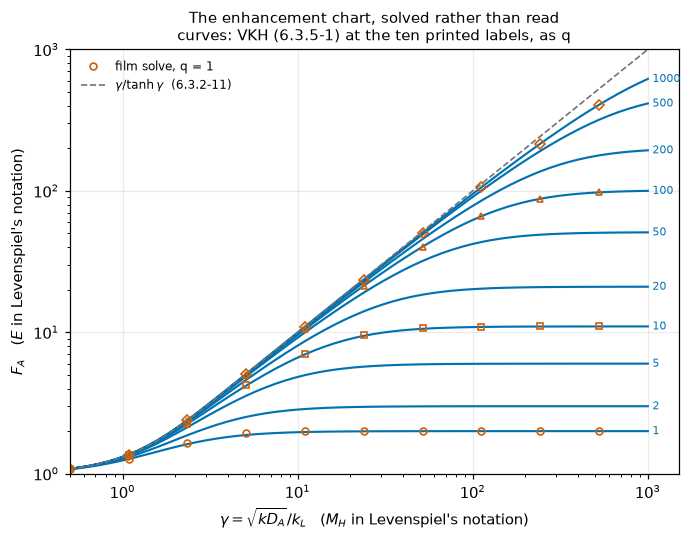

the same printed label, the two books' plateaux
  label  Froment 1+q  Levenspiel E_i    ratio
      1            2               1   2.0000
      2            3               2   1.5000
      5            6               5   1.2000
     10           11              10   1.1000
     20           21              20   1.0500
     50           51              50   1.0200
    100          101             100   1.0100
    200          201             200   1.0050
    500          501             500   1.0020
   1000         1001            1000   1.0010

worst at the smallest label: 2x   (100 %); least at the largest: 1.0010
the same abscissa is drawn over different ranges: Froment 0.5 to 1000, Levenspiel 0.1 to 1000
(this page searches Froment's, the narrower one)
computed VKH curves reach 1 + q at gamma = 1e6 to 1.00e-06 relative


In [6]:
GAMMA = np.geomspace(G_LO, G_HI, 60)
CURVES = {L: np.array([f_a_vkh(g, float(L)) for g in GAMMA]) for L in LABELS}
SOLVED = {L: np.array([REF.f_a(g, float(L))[0] for g in GAMMA[::6]])
          for L in (1, 10, 100, 1000)}

fig, ax = plt.subplots(figsize=(6.4, 5.0))
for L in LABELS:
    ax.loglog(GAMMA, CURVES[L], color=C_BLUE, lw=1.4)
    ax.annotate(f"{L}", (GAMMA[-1], CURVES[L][-1]), fontsize=7.5,
                xytext=(3, -2), textcoords="offset points", color=C_BLUE)
for L, mk in zip((1, 10, 100, 1000), ("o", "s", "^", "D")):
    ax.loglog(GAMMA[::6], SOLVED[L], mk, ms=4.5, mfc="none", mew=1.1,
              color=C_ORANGE, label=f"film solve, q = {L}" if L == 1 else None)
ax.loglog(GAMMA, GAMMA / np.tanh(GAMMA), color=C_GREY, lw=1.1, ls="--",
          label=r"$\gamma/\tanh\gamma$  (6.3.2-11)")
ax.set_xlim(G_LO, G_HI * 1.5)
ax.set_ylim(printed("froment_FA_axis_lo"), printed("froment_FA_axis_hi"))
ax.set_xlabel(r"$\gamma = \sqrt{kD_A}/k_L$   ($M_H$ in Levenspiel's notation)")
ax.set_ylabel(r"$F_A$   ($E$ in Levenspiel's notation)")
ax.set_title("The enhancement chart, solved rather than read\n"
             "curves: VKH (6.3.5-1) at the ten printed labels, as q",
             fontsize=9.5)
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

# ---- the plateau each book's own label implies -----------------------------
PLATEAU_FR = np.array([1.0 + L for L in LABELS])     # Froment: label = q
PLATEAU_LEV = np.array([float(L) for L in LABELS])   # Levenspiel: label = E_i
LABEL_RATIO = PLATEAU_FR / PLATEAU_LEV
CHART_LABEL_MAX_RATIO = float(LABEL_RATIO.max())
print("the same printed label, the two books' plateaux")
print(f'{"label":>7}{"Froment 1+q":>13}{"Levenspiel E_i":>16}{"ratio":>9}')
for L, a, b, r in zip(LABELS, PLATEAU_FR, PLATEAU_LEV, LABEL_RATIO):
    print(f"{L:7d}{a:13.0f}{b:16.0f}{r:9.4f}")
print(f"\nworst at the smallest label: {CHART_LABEL_MAX_RATIO:.4g}x"
      f"   ({100 * (CHART_LABEL_MAX_RATIO - 1):.4g} %);"
      f" least at the largest: {LABEL_RATIO.min():.4f}")
print(f"the same abscissa is drawn over different ranges: Froment"
      f" {printed('froment_gamma_axis_lo'):g} to {printed('froment_gamma_axis_hi'):g},"
      f" Levenspiel {printed('lev_MH_axis_lo'):g} to {printed('lev_MH_axis_hi'):g}"
      f"\n(this page searches Froment's, the narrower one)")
# the computed curve must actually reach the plateau its label implies
PLATEAU_ERR = max(abs(f_a_vkh(1e6, float(L)) / (1.0 + L) - 1) for L in LABELS)
print(f"computed VKH curves reach 1 + q at gamma = 1e6 to {PLATEAU_ERR:.2e} relative")

### 2. Where the approximation is worst, root-found

The error $\varepsilon(\gamma, q) = F_A^{\mathrm{VKH}}/F_A^{\mathrm{film}} - 1$
is a smooth surface with one interior extremum. It is located by root-finding
$\partial\varepsilon/\partial\ln\gamma = 0$ at fixed $q$, and then
$\mathrm{d}\varepsilon^{*}/\mathrm{d}\ln q = 0$ over $q$ - **not** by taking the
largest value on a sweep. The difference is not cosmetic: the same search with
the root-finds disabled is one of the rows in the break table below.


In [7]:
def err_pct(g, q, film=None, vkh=None, **kw):
    """100 (F_VKH/F_film - 1) at one point of the chart."""
    film = REF if film is None else film
    vkh = f_a_vkh if vkh is None else vkh
    F, _ = film.f_a(g, q, **kw)
    return 100.0 * (vkh(g, q) - F) / F


N_SCAN, N_SCAN_Q, H_LN = 13, 9, 1e-3   # extremum scans in gamma and q, and the step in ln
G_MONO, N_MONO = 100.0, 21             # the line on which monotonicity is counted
D_MONO = 1e-6                          # a step counts when its ln changes by more than this
BETA_END_MAX = 1e-12                   # |beta(0)| at the axis end is below this


def block_worst(film=None, vkh=None, rootfind=True, n_scan=N_SCAN, labels=None,
                h=H_LN, **kw):
    """The worst point of the chart, and the depletion diagnostics there.

    Each extremum: a log scan of the whole window (n_scan points in gamma,
    N_SCAN_Q in q) brackets it, and Brent finds the root of the central
    difference of the error in ln gamma (or ln q) with step h.  The depletion
    thresholds are the single root of beta(0) - level found by a scan of the
    whole printed gamma axis (nan when there is none).
    """
    film = REF if film is None else film
    labels = LABELS if labels is None else labels

    def eps(g, q):
        return err_pct(g, q, film=film, vkh=vkh, **kw)

    def worst_at(q):
        return argext_log(lambda g: eps(g, q), G_LO, G_HI, n_scan, h=h,
                          rootfind=rootfind)[1]

    q_star, _, ok_q = argext_log(worst_at, Q_LO, Q_HI, N_SCAN_Q, h=h,
                                 rootfind=rootfind)
    g_star, e_star, ok_g = argext_log(lambda g: eps(g, q_star), G_LO, G_HI,
                                      n_scan, h=h, rootfind=rootfind)
    out = {"vkh_worst_rel_error_pct": e_star,
           "vkh_worst_gamma": g_star,
           "vkh_worst_q": q_star,
           "froment_10pct_claim_margin":
               printed("froment_vkh_validity_pct") / abs(e_star),
           "beta_interface_at_worst": film.f_a(g_star, q_star, **kw)[1],
           # the p. 340 wording of the same assumption, measured where the
           # p. 335 wording is most badly violated
           "beta_constancy_at_worst": film.beta_constancy(g_star, q_star, **kw),
           "vkh_worst_on_printed_labels_pct":
               float(max((argext_log(lambda g: eps(g, float(L)), G_LO, G_HI,
                                     n_scan, h=h, rootfind=rootfind)[1]
                          for L in labels), key=abs)),
           "_root_found": bool(ok_q and ok_g)}

    def beta_at(g):
        return film.f_a(g, q_star, **kw)[1]

    def at(g, f):                       # nan where a threshold does not exist
        return float("nan") if np.isnan(g) else f(g)

    g_half = unique_root_log(lambda g: beta_at(g) - 0.5, G_LO, G_HI, n_scan)
    g_99 = unique_root_log(lambda g: beta_at(g) - 0.01, G_LO, G_HI, n_scan)
    out.update({"gamma_at_half_depletion": g_half,
                "gamma_at_99pct_depletion": g_99,
                "vkh_error_at_half_depletion_pct": at(g_half, lambda g: eps(g, q_star)),
                "vkh_error_at_99pct_depletion_pct": at(g_99, lambda g: eps(g, q_star)),
                "vkh_error_at_full_depletion_pct": eps(G_HI, q_star),
                "beta_constancy_at_99pct_depletion":
                    at(g_99, lambda g: film.beta_constancy(g, q_star, **kw)),
                "_beta_constancy_at_half":
                    at(g_half, lambda g: film.beta_constancy(g, q_star, **kw)),
                "beta_interface_at_axis_end": abs(beta_at(G_HI))})
    # monotonicity of both assumption measures along the worst curve, on the
    # decade where beta(0) is still resolved: successive differences in ln
    gl = np.geomspace(G_LO, G_MONO, N_MONO)
    with np.errstate(invalid="ignore", divide="ignore"):
        d_b = np.diff(np.log([beta_at(g) for g in gl]))
        d_c = np.diff(np.log([film.beta_constancy(g, q_star, **kw) for g in gl]))
    out.update({"depletion_falls_steps": int(np.sum(d_b < -D_MONO)),
                "constancy_rises_steps": int(np.sum(d_c > D_MONO)),
                "_dlog_beta0": d_b, "_dlog_constancy": d_c})
    return out


W = block_worst()
G_STAR, Q_STAR = W["vkh_worst_gamma"], W["vkh_worst_q"]
print(f"worst error on the chart: {W['vkh_worst_rel_error_pct']:+.4f} %"
      f"  at gamma = {G_STAR:.4f}, q = {Q_STAR:.4f}"
      f"  (E_i = 1 + q = {1 + Q_STAR:.4f})")
print(f"  found by root-finding, not by sampling: {W['_root_found']}")
print(f"  worst over the ten PRINTED curve labels only:"
      f" {W['vkh_worst_on_printed_labels_pct']:+.4f} %")
print(f"  the book's printed claim is {printed('froment_vkh_validity_pct'):g} percent;"
      f" margin {W['froment_10pct_claim_margin']:.4f}x")
print(f"\nVKH is an UNDER-estimate everywhere it was evaluated:"
      f" sign of the worst error {np.sign(W['vkh_worst_rel_error_pct']):+.0f}")
for q in (0.05, 0.1, 0.5, Q_STAR, 5.0, 50.0, 500.0):
    e = argext_log(lambda g: err_pct(g, q), G_LO, G_HI, 13)[1]
    print(f"   q = {q:8.4f}   worst over gamma {e:+8.4f} %")

worst error on the chart: -2.7955 %  at gamma = 4.7279, q = 1.5217  (E_i = 1 + q = 2.5217)
  found by root-finding, not by sampling: True
  worst over the ten PRINTED curve labels only: -2.7294 %
  the book's printed claim is 10 percent; margin 3.5772x

VKH is an UNDER-estimate everywhere it was evaluated: sign of the worst error -1


   q =   0.0500   worst over gamma  -0.3134 %
   q =   0.1000   worst over gamma  -0.5928 %


   q =   0.5000   worst over gamma  -1.9984 %
   q =   1.5217   worst over gamma  -2.7955 %
   q =   5.0000   worst over gamma  -1.8067 %
   q =  50.0000   worst over gamma  -0.2769 %
   q = 500.0000   worst over gamma  -0.0282 %


### 3. The assumption, measured - in both of the book's wordings

**The book states the assumption twice, and the two statements are not the same
test.** Book p. 335, beside the chart, says the intermediate curves *"were
calculated by Van Krevelen and Hoftijzer [1948] under the assumption that B is
only weakly depleted near the interface"* - and adds, in the same breath,
*"For moderately fast reactions, this assumption was reasonably confirmed by
more rigorous computations."* Book p. 340, five lines above (6.3.5-1) itself,
says they proceeded *"by assuming that the concentration of B remains
approximately constant close to the interface"*.

The first wording is about the **level** of depletion at the interface, which
$\beta(0)$ measures exactly. The second is about the **constancy** of $\beta$
over the zone where the reaction happens, which $\beta(0)$ does not measure at
all: it is measured here by the rate-weighted mean
$\bar\beta = \int \alpha\beta\cdot\beta\,\mathrm{d}\xi \big/
\int \alpha\beta\,\mathrm{d}\xi$ divided by $\beta(0)$, which is 1 when
$\beta$ is constant where it matters. Both are printed below, so the finding
does not depend on which wording is tested.

**Neither survives as an explanation of the error.** At the worst point $B$ at
the interface is already down to a sixth of its bulk value and $\bar\beta$ is
twice $\beta(0)$ - neither wording is nearly satisfied there - and yet as
$\gamma$ grows further, with $B$ consumed *completely* and $\bar\beta/\beta(0)$
running away without bound, the approximation becomes **exact**. The error
vanishes at both ends and peaks in between, and the two assumption measures are
monotone in $\gamma$, so no monotone function of either can order it.

The reason is visible in the profiles: at large $\gamma$ the reaction collapses
onto a plane and $F_A \to 1 + q$, a limit the approximation reproduces by
construction whatever it assumed on the way there. Note also what the page is
*not* saying: Froment's own claim on p. 335 is qualified to *moderately fast*
reactions, and the worst point found above sits inside that band - between his
printed $\gamma > 3$ line and the instantaneous ones - and still errs by less
than the 10 percent he prints. Measured, his qualified sentence stands. What
fails is the unqualified reading of it, that weak depletion is *why* the
approximation works.


book p.335  "They were calculated by Van Krevelen and Hoftijzer [1948] under the assumption that B is only weakly depleted near the interface. For moderately fast reactions, this assumption was reasonably confirmed by more rigorous computations."

book p.340  "Van Krevelen and Hoftijzer [1948] dealt with this situation in a way analogous to that applied to pseudo-first-order kinetics, namely, by assuming that the concentration of B remains approximately constant close to the interface."

at q = 1.5217, the worst curve of the whole chart:
                               gamma     beta(0)  beta_w/beta(0)    F_A film   VKH error
  B half gone                 2.2036  5.0000e-01           1.208      1.7609    -1.8304 %
  the worst point             4.7279  1.6474e-01           2.115      2.2710    -2.7955 %
  B 99 % gone                13.0378  1.0000e-02            19.2      2.5065    -1.5035 %
  B gone (axis end)        1000.0000     < 1e-12               -      2.5217    -0.0004 %

  on 2


over the whole 612-point map the largest error is negative: VKH lies above the film solve at 0 points
this one is a THEOREM and the map only illustrates it, so it is a check that
could only fail by numerical accident:  alpha'' = gamma^2 alpha beta >= 0, so alpha' rises
from alpha'(0) = -F_A and beta' = (alpha' + F_A)/q >= 0, i.e. beta(xi) >= beta(0) everywhere.
Write T(F) for the pseudo-first-order enhancement with beta frozen at 1 - (F-1)/q, which is
exactly beta(0); (6.3.5-1) says F_VKH = T(F_VKH).  The true film sees beta >= beta(0), hence
F_film >= T(F_film); T is strictly decreasing, so F - T(F) is strictly increasing and
F_film >= F_VKH for EVERY (gamma, q).  The map is drawn on the single n_x = 800 graded
grid, which is enough for a sign; every NUMBER reported comes from the extrapolated reference.
the worst point sits at gamma = 4.7279, on the film side of the book's own regime line - it prints "The reaction is essentially completed in the film when gamma > 3" (book p.331) and

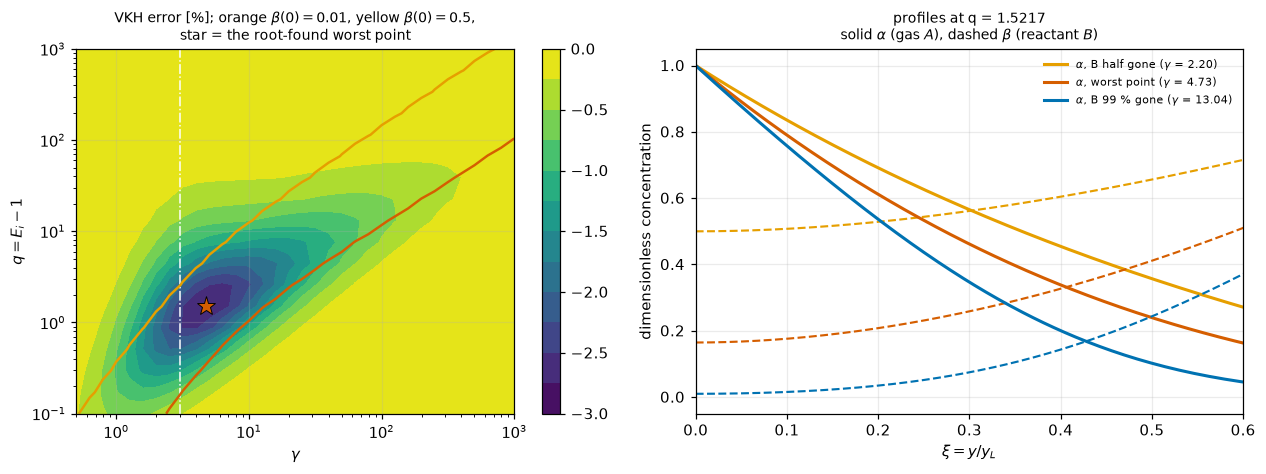

In [8]:
# the two wordings, printed from the CSV rather than retyped here
for k in ("froment_assumption_p335", "froment_assumption_p340"):
    print(f'book p.{PRN.loc[k, "book_page"]}  "{quoted(k)}"\n')
for k, words in (("froment_assumption_p335", "weakly depleted"),
                 ("froment_assumption_p335", "reasonably confirmed"),
                 ("froment_assumption_p340", "remains approximately constant")):
    if words not in quoted(k):
        raise ValueError(f"{k} no longer contains {words!r}")

print(f"at q = {Q_STAR:.4f}, the worst curve of the whole chart:")
print(f'{"":26s}{"gamma":>10}{"beta(0)":>12}{"beta_w/beta(0)":>16}'
      f'{"F_A film":>12}{"VKH error":>12}')
rows = [("B half gone", W["gamma_at_half_depletion"], 0.5,
         W["_beta_constancy_at_half"], W["vkh_error_at_half_depletion_pct"]),
        ("the worst point", G_STAR, W["beta_interface_at_worst"],
         W["beta_constancy_at_worst"], W["vkh_worst_rel_error_pct"]),
        ("B 99 % gone", W["gamma_at_99pct_depletion"], 0.01,
         W["beta_constancy_at_99pct_depletion"],
         W["vkh_error_at_99pct_depletion_pct"]),
        ("B gone (axis end)", G_HI, None,
         None, W["vkh_error_at_full_depletion_pct"])]
for name, g, b, c, e in rows:
    print(f"  {name:24s}{g:10.4f}{(f'< {BETA_END_MAX:g}' if b is None else f'{b:.4e}'):>12}"
          f"{('-' if c is None else f'{c:.4g}'):>16}"
          f"{REF.f_a(g, Q_STAR)[0]:12.4f}{e:+11.4f} %")
print(f"\n  on {N_MONO} log-spaced gamma from {G_LO:g} to {G_MONO:g} along this curve,"
      f" p.335's test, beta(0), falls")
print(f"  on {W['depletion_falls_steps']} of the {N_MONO - 1} steps, and p.340's test,"
      f" beta_w/beta(0), rises on {W['constancy_rises_steps']}:")
print(f"  both are monotone, and the error is not: it peaks at gamma = {G_STAR:.4f}.")
print(f"  beta(0) at the axis end is numerically zero, of magnitude below"
      f" {BETA_END_MAX:g}, far below anything this")
print(f"  discretisation resolves and with a sign set by round-off, so the constancy"
      f" ratio, which divides by")
print(f"  it, is left out of that row rather than printed as a number.")
G_MID = 100.0
B_MID = REF.f_a(G_MID, Q_STAR)[1]
C_MID = REF.beta_constancy(G_MID, Q_STAR)
E_MID = err_pct(G_MID, Q_STAR)
print(f"\n  One decade lower, where beta(0) is still meaningful:  at gamma ="
      f" {G_MID:g}, beta(0) = {B_MID:.3e}")
print(f"  and beta_w/beta(0) = {C_MID:.4g}, so p.340's constancy assumption is out by"
      f" {np.log10(C_MID):.0f} orders of")
print(f"  magnitude - and the error there is {E_MID:+.4f} %,"
      f" {abs(W['vkh_worst_rel_error_pct'] / E_MID):.0f} times SMALLER"
      f" than at the worst point.")
# The constancy ratio is EXTRAPOLATED like everything else, and it has to be:
# a ratio of two integrals of the same profile does NOT cancel the grid once
# beta is a thin exponential.  Both gaps are measured here, not asserted.
C_FINE_STAR = FILM.beta_constancy(G_STAR, Q_STAR)
C_FINE_MID = FILM.beta_constancy(G_MID, Q_STAR)
print(f"\n  the constancy ratio is Richardson-extrapolated on the same two grids"
      f" as F_A, and needs to be:")
print(f"    at the worst point the fine n_x = {FILM.n_x} grid alone gives"
      f" {C_FINE_STAR:.4g} against {W['beta_constancy_at_worst']:.4g}"
      f"   ({abs(C_FINE_STAR / W['beta_constancy_at_worst'] - 1):.1e})")
print(f"    at gamma = {G_MID:g} it gives"
      f" {C_FINE_MID:.3g} against {C_MID:.3g}"
      f"   ({abs(C_FINE_MID / C_MID - 1):.1e})")
print(f"  so the grid all but cancels where the headline lives and does NOT at the"
      f" top of the range: the")
print(f"  one-grid shortcut on this diagnostic would cost"
      f" {abs(C_FINE_MID / C_MID - 1) / abs(C_FINE_STAR / W['beta_constancy_at_worst'] - 1):.0e}"
      f" times more at gamma = {G_MID:g}")
print(f"  than at the point it would be justified on, which is why it is not taken.")
print(f"\nthe two depletion thresholds are ROOT-FOUND on beta(0), not sampled:"
      f"\n  beta(0) = 0.5  at gamma = {W['gamma_at_half_depletion']:.4f}"
      f"   (residual below 1e-9: {abs(REF.f_a(W['gamma_at_half_depletion'], Q_STAR)[1] - 0.5) < 1e-9})"
      f"\n  beta(0) = 0.01 at gamma = {W['gamma_at_99pct_depletion']:.4f}"
      f"   (residual below 1e-9: {abs(REF.f_a(W['gamma_at_99pct_depletion'], Q_STAR)[1] - 0.01) < 1e-9})")

# ---- the error map, and the depletion contours on top of it ----------------
GG = np.geomspace(G_LO, G_HI, 34)
QQ = np.geomspace(Q_LO, Q_HI, 18)


def error_map(film=None, vkh=None, **kw):
    """VKH error [%] and beta(0) on the GG x QQ map (single graded grid)."""
    film = FILM if film is None else film
    vkh = f_a_vkh if vkh is None else vkh
    eps, bet = np.zeros((QQ.size, GG.size)), np.zeros((QQ.size, GG.size))
    for i, q in enumerate(QQ):
        for j, g in enumerate(GG):
            F, b = film.f_a(g, q, **kw)
            eps[i, j], bet[i, j] = 100.0 * (vkh(g, q) - F) / F, b
    return eps, bet


EPS, BET = error_map()
N_OVER = int(np.sum(EPS > 0.0))
print(f"\nover the whole {EPS.size}-point map the largest error is"
      f" negative: VKH lies above the film solve at {N_OVER} points")
print("this one is a THEOREM and the map only illustrates it, so it is a check that"
      "\ncould only fail by numerical accident:  alpha'' = gamma^2 alpha beta >= 0,"
      " so alpha' rises"
      "\nfrom alpha'(0) = -F_A and beta' = (alpha' + F_A)/q >= 0, i.e. beta(xi) >="
      " beta(0) everywhere."
      "\nWrite T(F) for the pseudo-first-order enhancement with beta frozen at"
      " 1 - (F-1)/q, which is"
      "\nexactly beta(0); (6.3.5-1) says F_VKH = T(F_VKH).  The true film sees"
      " beta >= beta(0), hence"
      "\nF_film >= T(F_film); T is strictly decreasing, so F - T(F) is strictly"
      " increasing and"
      "\nF_film >= F_VKH for EVERY (gamma, q).  The map is drawn on the single"
      f" n_x = {FILM.n_x} graded"
      "\ngrid, which is enough for a sign; every NUMBER reported comes from the"
      " extrapolated reference.")
print(f"the worst point sits at gamma = {G_STAR:.4f}, on the film side of the"
      f" book's own regime line - it prints"
      f' "{quoted("froment_film_completion_gamma")}" (book p.'
      f'{PRN.loc["froment_film_completion_gamma", "book_page"]}) and'
      f' "{quoted("froment_bulk_reaction_gamma")}"')

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.4))
cf = axes[0].contourf(GG, QQ, EPS, levels=np.linspace(-3.0, 0.0, 13), cmap="viridis")
for _g, _ls in ((printed("froment_bulk_reaction_gamma"), ":"),
                (printed("froment_film_completion_gamma"), "-.")):
    if G_LO <= _g <= G_HI:
        axes[0].axvline(_g, color="w", lw=1.0, ls=_ls)
axes[0].contour(GG, QQ, BET, levels=[0.01, 0.5], colors=[C_ORANGE, C_YELLOW],
                linewidths=1.6)
axes[0].plot([G_STAR], [Q_STAR], "*", ms=13, color=C_ORANGE, mec="k", mew=0.6)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel(r"$\gamma$"); axes[0].set_ylabel("$q = E_i - 1$")
axes[0].set_title("VKH error [%]; orange $\\beta(0)=0.01$, yellow $\\beta(0)=0.5$,\n"
                  "star = the root-found worst point", fontsize=9)
fig.colorbar(cf, ax=axes[0])

for name, g, c in (("B half gone", W["gamma_at_half_depletion"], C_YELLOW),
                   ("worst point", G_STAR, C_ORANGE),
                   ("B 99 % gone", W["gamma_at_99pct_depletion"], C_BLUE)):
    u = FILM.solve(g, Q_STAR)
    axes[1].plot(FILM.x_c, u[:, 0], color=c, lw=2.0,
                 label=rf"$\alpha$, {name} ($\gamma$ = {g:.2f})")
    axes[1].plot(FILM.x_c, u[:, 1], color=c, lw=1.4, ls="--")
axes[1].set_xlim(0, 0.6)
axes[1].set_xlabel(r"$\xi = y/y_L$")
axes[1].set_ylabel("dimensionless concentration")
axes[1].set_title(f"profiles at q = {Q_STAR:.4f}\n"
                  r"solid $\alpha$ (gas $A$), dashed $\beta$ (reactant $B$)",
                  fontsize=9)
axes[1].legend(frameon=False, fontsize=7.5)
fig.tight_layout()
plt.show()

### 4. Levenspiel's three expansions, and what each one expands

Levenspiel prints three "more precisely" corrections in the annotation boxes of
Fig. 23.4. They are an independent transcription of the same result by a
different author in a different notation, so every constant in them checks a
constant in Froment's equation - and the two of them that can be checked
against the *film equations* as well turn out to behave very differently.

- **Small $M_H$:** $E \cong 1 + M_H^2/3$. This is the Taylor series of
  $\gamma/\tanh\gamma$, so the constant 3 checks Froment's (6.3.2-11)
  directly. It is good to 1 % up to a root-found $M_H$ reported below.
- **Pseudo-first-order branch,** declared for $E_i > 5M_H$:
  $E = M_H\left(1 - (M_H-1)/2E_i\right)$. Expanding Froment's (6.3.5-1) in the
  same limit gives the same expression with $E_i - 1$ where Levenspiel prints
  $E_i$ - the difference between the two books' groups, second order in that
  branch. Both are evaluated against the film solve at the boundary of the
  declared domain.
- **Instantaneous branch,** declared for $E_i < M_H/5$:
  $E \cong E_i - E_i^2(E_i-1)/M_H^2$. **This one is the asymptote of the
  approximation, not of the equations,** and both halves of that statement are
  exact rather than empirical. Put $F_A = 1 + q - d$ into (6.3.5-1): for large
  $\gamma$ it gives $\gamma\sqrt{d/q} \to x$ with $x = (1 + q)\tanh x$, i.e.
  $d \to q x^2/\gamma^2$, which is Levenspiel's $E_i^2(E_i-1)/M_H^2$ only
  when $\tanh x \to 1$, that is for large $E_i$ too. The film's own deficit,
  on the other hand, is fixed by
  the first integral of the two film equations, $q\,\beta(0) = 1 + q - F_A$: it
  equals $q\,\beta(0)$ identically, and $\beta(0)$ is the interfacial value of
  a reaction layer whose thickness goes as $1/\gamma$, so it is exponentially
  small and can follow no power law at all. The measured local exponent
  steepens over successive octaves, and the printed correction runs further and
  further above the truth.


(a) 1 + M_H^2/3 stays within 1 % of the film solve up to M_H = 0.7231  (root-found)

(b) at the declared boundary E_i = 5 M_H, with M_H = 10 and E_i = 50:
      E = M_H                               +9.3004 %
      Levenspiel, printed 2 E_i             -0.5366 %
      same expansion of (6.3.5-1), 2(E_i-1) -0.7374 %
    -> the correction is worth 17.33x, and the two books' groups differ by 0.2008 percentage points there

(c) instantaneous branch, E_i = 20:  deficit E_i - E against the printed E_i^2(E_i-1)/M_H^2
     M_H    film solve           VKH       printed  printed/film
      50    2.2491e+00    2.3639e+00    3.0400e+00          1.35
     100    5.9591e-01    7.0720e-01    7.6000e-01          1.28
     200    1.0985e-01    1.8647e-01    1.9000e-01          1.73
     400    1.0860e-02    4.7276e-02    4.7500e-02          4.37
     800    2.6840e-04    1.1861e-02    1.1875e-02         44.24
  local exponent d ln(deficit)/d ln M_H, octave by octave
    film solve : [-1.9162, -2.4396, 

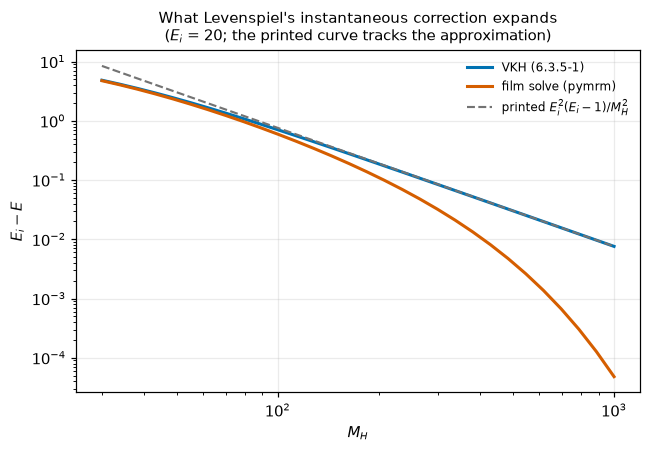

In [9]:
DEFICIT_M = (50.0, 100.0, 200.0, 400.0, 800.0)


def block_lev(film=None, vkh=None, small_coeff=None, pfo_denom=None,
              pfo_offset=None, inst_power=None, deficit_film=None,
              bvp_tol=1e-10, **kw):
    """Levenspiel's three printed expansions, tested against both routes."""
    film = REF if film is None else film
    vkh = f_a_vkh if vkh is None else vkh
    c3 = printed("lev_small_M_coeff") if small_coeff is None else small_coeff
    c2 = printed("lev_pfo_correction_denom") if pfo_denom is None else pfo_denom
    c1 = printed("lev_pfo_correction_offset") if pfo_offset is None else pfo_offset
    cp = printed("lev_inst_correction_power") if inst_power is None else inst_power
    out = {}

    # (a) the small-M_H expansion, 1 % threshold ROOT-FOUND
    q_a = 4.0
    out["lev_small_M_1pct_threshold"] = unique_root_log(
        lambda m: abs((1.0 + m**2 / c3) / film.f_a(m, q_a, **kw)[0] - 1) - 0.01,
        G_LO, G_HI, N_SCAN)

    # (b) the pseudo-first-order branch, AT the boundary E_i = 5 M_H it declares
    m_b = 10.0
    Ei_b = printed("lev_pfo_threshold") * m_b
    q_b = Ei_b - 1.0
    F_b = film.f_a(m_b, q_b, **kw)[0]
    out["lev_pfo_expansion_err_pct"] = 100.0 * (
        m_b * (1.0 - (m_b - c1) / (c2 * Ei_b)) / F_b - 1.0)
    out["vkh_form_pfo_expansion_err_pct"] = 100.0 * (
        m_b * (1.0 - (m_b - c1) / (c2 * q_b)) / F_b - 1.0)
    out["uncorrected_E_eq_M_err_pct"] = 100.0 * (m_b / F_b - 1.0)

    # (c) the instantaneous branch
    Ei_c = 20.0
    q_c = Ei_c - 1.0
    fd = film if deficit_film is None else deficit_film

    def pred(m):
        return Ei_c**cp * (Ei_c - 1.0) / m**2

    def dnum(m):
        return Ei_c - fd.f_a(m, q_c, **kw)[0]

    out["lev_inst_asymptote_ratio_vkh"] = (Ei_c - vkh(400.0, q_c)) / pred(400.0)
    out["lev_inst_asymptote_ratio_num"] = dnum(400.0) / pred(400.0)
    out["lev_inst_overstatement_factor"] = pred(800.0) / dnum(800.0)
    # the VKH deficit against q(1+q)^2/gamma^2 at the axis end of the worst curve,
    # where q is far from large E_i: the limit is q x^2/gamma^2 with
    # x = (1 + q) tanh x, so the ratio stays below one
    qw = W["vkh_worst_q"]
    out["vkh_deficit_over_lev_correction_axis_end"] = (
        (1.0 + qw - vkh(G_HI, qw)) * G_HI**2 / (qw * (1.0 + qw)**2))
    dn = [dnum(m) for m in DEFICIT_M]
    dv = [Ei_c - vkh(m, q_c) for m in DEFICIT_M]
    # abs() only so that a break row which drives a deficit negative still
    # returns a number instead of a nan; every baseline deficit is positive.
    ex = [float(np.log(abs(a[i + 1] / a[i]))
                / np.log(DEFICIT_M[i + 1] / DEFICIT_M[i]))
          for a in (dn, dv) for i in range(len(DEFICIT_M) - 1)]
    n_gap = len(DEFICIT_M) - 1
    out["inst_deficit_exponent_num_steepest"] = min(ex[:n_gap])
    out["inst_deficit_exponent_vkh_finest"] = ex[2 * n_gap - 1]
    out["_exponents_num"], out["_exponents_vkh"] = ex[:n_gap], ex[n_gap:]
    out["_deficit_num"], out["_deficit_vkh"] = dn, dv
    # TWO INDEPENDENT METHODS, one of them also refined - not three routes.
    # pymrm finite volumes and scipy's collocation share no assembly; the
    # middle entry is the same assembly on a finer, differently graded mesh, so
    # it prices the discretisation of the first and not its formulation.
    alt = graded_film(2 * fd.n_x, fd.stretch + 1.0)
    three = [dnum(800.0), Ei_c - alt.f_a(800.0, q_c, **kw)[0],
             Ei_c - f_a_bvp(800.0, q_c, tol=bvp_tol)[0]]
    out["inst_deficit_routes_max_rel_diff"] = max(three) / min(three) - 1.0
    out["_three"] = three
    # the EXACT reason the film deficit has no power law: the first integral of
    # the two film equations makes it q*beta(0) identically, and beta(0) at the
    # interface is exponentially small in gamma.
    out["_beta0_at_deficit"] = fd.f_a(800.0, q_c, **kw)[1]
    return out


L = block_lev()
print(f"(a) 1 + M_H^2/{printed('lev_small_M_coeff'):g} stays within 1 % of the film"
      f" solve up to M_H = {L['lev_small_M_1pct_threshold']:.4f}  (root-found)")
_m, _Ei = 10.0, printed("lev_pfo_threshold") * 10.0
print(f"\n(b) at the declared boundary E_i = {printed('lev_pfo_threshold'):g} M_H,"
      f" with M_H = {_m:g} and E_i = {_Ei:g}:")
print(f"      E = M_H                              {L['uncorrected_E_eq_M_err_pct']:+8.4f} %")
print(f"      Levenspiel, printed 2 E_i            {L['lev_pfo_expansion_err_pct']:+8.4f} %")
print(f"      same expansion of (6.3.5-1), 2(E_i-1){L['vkh_form_pfo_expansion_err_pct']:+8.4f} %")
print(f"    -> the correction is worth"
      f" {abs(L['uncorrected_E_eq_M_err_pct'] / L['lev_pfo_expansion_err_pct']):.2f}x,"
      f" and the two books' groups differ by"
      f" {abs(L['lev_pfo_expansion_err_pct'] - L['vkh_form_pfo_expansion_err_pct']):.4f}"
      f" percentage points there")
print(f"\n(c) instantaneous branch, E_i = 20:  deficit E_i - E against the printed"
      f" E_i^2(E_i-1)/M_H^2")
print(f'{"M_H":>8}{"film solve":>14}{"VKH":>14}{"printed":>14}{"printed/film":>14}')
for m, dn, dv in zip(DEFICIT_M, L["_deficit_num"], L["_deficit_vkh"]):
    p = 20.0**2 * 19.0 / m**2
    print(f"{m:8.0f}{dn:14.4e}{dv:14.4e}{p:14.4e}{p / dn:14.2f}")
print(f"  local exponent d ln(deficit)/d ln M_H, octave by octave")
print(f"    film solve : {[round(e, 4) for e in L['_exponents_num']]}")
print(f"    VKH        : {[round(e, 4) for e in L['_exponents_vkh']]}")
print(f"  the VKH deficit converges on the printed -2; the film solve's does not"
      f"\n  the M_H = 800 deficit by TWO INDEPENDENT METHODS, the first also refined:"
      f"\n    pymrm FV, extrapolated (n_x = {FILM_C.n_x}, {FILM.n_x}, s = 8)"
      f"  {L['_three'][0]:.3e}"
      f"\n    pymrm FV, n_x = {2 * FILM.n_x}, s = 9 (the same assembly, refined)  "
      f"{L['_three'][1]:.3e}"
      f"\n    scipy collocation (no assembly in common)               "
      f"{L['_three'][2]:.3e}"
      f"\n  max relative spread below 1e-3"
      f" (here {L['inst_deficit_routes_max_rel_diff']:.1e}); the M_H = 800 deficit, E_i - F_A,"
      f"\n  is about 1.3e-5 of F_A, so its last digits differ between BLAS"
      f" kernels) - far below the\n  {L['lev_inst_overstatement_factor']:.1f}x it"
      f" supports")
print(f"\n  WHY there can be no power law, exactly.  Subtracting the two film"
      f" equations gives"
      f"\n  (beta - alpha/q)'' = 0, and the four boundary conditions close it:"
      f" q beta(0) = 1 + q - F_A"
      f"\n  identically, so the film deficit E_i - E IS q beta(0) - and beta(0) is"
      f" the interfacial"
      f"\n  value of a WKB-thin reaction layer, exponentially small in M_H."
      f"  At M_H = 800 the film"
      f"\n  solve gives beta(0) = {L['_beta0_at_deficit']:.4e}, so"
      f" q beta(0) = {19.0 * L['_beta0_at_deficit']:.4e} against the deficit"
      f" {L['_three'][0]:.4e}.")
print(f"  The VKH deficit, by contrast, is a power law exactly: putting"
      f" F_A = 1 + q - d in (6.3.5-1)"
      f"\n  gives gamma sqrt(d/q) -> x with x = (1 + q) tanh x, i.e. d -> q x^2/gamma^2,"
      f" which is Levenspiel's"
      f"\n  E_i^2(E_i - 1)/M_H^2 only for large E_i too (on the worst curve the VKH"
      f" deficit at the axis end is"
      f"\n  {L['vkh_deficit_over_lev_correction_axis_end']:.4f} of it).  His 'more"
      f" precisely' correction is an asymptote of the"
      f"\n  APPROXIMATION, not of the equations - which is why it tracks VKH to"
      f" {L['lev_inst_asymptote_ratio_vkh']:.4f} and the film"
      f"\n  solve to only {L['lev_inst_asymptote_ratio_num']:.4f}.")
print(f"  And {L['lev_inst_overstatement_factor']:.0f}x too big is that factor of a"
      f" small correction: at M_H = 800 the"
      f" uncorrected E = E_i is already"
      f"\n  within {100 * L['_three'][0] / 20.0:.5f} % of the film solve, so"
      f" Levenspiel's correction is there WORSE than"
      f"\n  leaving it out - it moves E away from the truth by"
      f" {100 * (20.0**2 * 19.0 / 800.0**2 - L['_three'][0]) / 20.0:.5f} percentage"
      f" points.")

fig, ax = plt.subplots(figsize=(6.0, 4.2))
MM = np.geomspace(30.0, 1000.0, 30)
ax.loglog(MM, [20.0 - f_a_vkh(m, 19.0) for m in MM], color=C_BLUE, lw=2.0,
          label="VKH (6.3.5-1)")
ax.loglog(MM, [20.0 - REF.f_a(m, 19.0)[0] for m in MM], color=C_ORANGE, lw=2.0,
          label="film solve (pymrm)")
ax.loglog(MM, 20.0**2 * 19.0 / MM**2, color=C_GREY, ls="--", lw=1.4,
          label=r"printed $E_i^2(E_i-1)/M_H^2$")
ax.set_xlabel("$M_H$"); ax.set_ylabel("$E_i - E$")
ax.set_title("What Levenspiel's instantaneous correction expands\n"
             "($E_i$ = 20; the printed curve tracks the approximation)",
             fontsize=9.5)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## Validation

Six checks, none of which uses fitted data because there is none. Two of them
are about the **baseline itself**, because the whole page is a set of errors
quoted against it: the extrapolated reference is compared with an independent
solver family and with a finer extrapolation of itself, and the grid study is
run on the graded *and* the uniform grid so that what grading buys and what it
costs are both on the page.


In [10]:
def block_routes(film=None, ref=None, vkh=None, stretch=None, newton_tol=1e-10,
                 bvp_tol=1e-10, bc_beta_bulk="dirichlet", n_grid=(100, 200, 400, 800),
                 **kw):
    """Two solvers for the film, two for the implicit relation, and the grid."""
    film = FILM if film is None else film
    ref = REF if ref is None else ref
    vkh = f_a_vkh if vkh is None else vkh
    s = film.stretch if stretch is None else stretch
    pts = [(g, q) for q in (1.0, 4.0, 19.0, 99.0)
           for g in (1.0, 3.0, 10.0, 30.0, 100.0)]
    col = {p: f_a_bvp(*p, tol=bvp_tol) for p in pts}
    out = {
        "fv_vs_bvp_max_rel_diff": float(max(
            abs(film.f_a(g, q, tol=newton_tol, **kw)[0] / col[(g, q)][0] - 1.0)
            for g, q in pts)),
        "fv_vs_bvp_max_abs_diff_beta": float(max(
            abs(film.f_a(g, q, tol=newton_tol, **kw)[1] - col[(g, q)][1])
            for g, q in pts)),
        # the SAME comparison for the baseline this page actually reports
        "ref_vs_bvp_max_rel_diff": float(max(
            abs(ref.f_a(g, q, tol=newton_tol, **kw)[0] / col[(g, q)][0] - 1.0)
            for g, q in pts)),
        # and the baseline against a finer extrapolation of itself: the
        # refinement evidence for the reference, not for one grid of it
        "ref_self_refinement_max_rel_diff": float(max(
            abs(ref.f_a(g, q, tol=newton_tol, **kw)[0]
                / REF_FINE.f_a(g, q, tol=newton_tol, **kw)[0] - 1.0)
            for g, q in pts)),
        # the first integral of the two film equations, which no discretisation
        # is told about: q beta(0) = 1 + q - F_A.  Normalised by 1 + q because
        # at large gamma both sides are round-off.
        "first_integral_max_abs_resid": float(max(
            abs(q * ref.f_a(g, q, tol=newton_tol, **kw)[1]
                - (1.0 + q - ref.f_a(g, q, tol=newton_tol, **kw)[0])) / (1.0 + q)
            for g, q in pts)),
        "vkh_two_routes_max_rel_diff": float(max(
            abs(vkh(g, q) / f_a_vkh_route_b(g, q) - 1.0) for g, q in pts)),
        "vkh_pfo_limit_max_rel_error": float(max(
            abs(vkh(g, 1e10) / (g / np.tanh(g)) - 1.0)
            for g in np.geomspace(G_LO, 300.0, 40))),
        "vkh_instantaneous_limit_rel_error": float(abs(vkh(1e6, 19.0) / 20.0 - 1.0)),
    }
    g_ref, q_ref = 10.0, 4.0
    exact = f_a_bvp(g_ref, q_ref, tol=1e-11)[0]

    def f_on(n, st):
        return Film(n_x=n, stretch=st, bc_beta_bulk=bc_beta_bulk).f_a(
            g_ref, q_ref, tol=newton_tol, **kw)[0]

    # orders from successive differences on the graded ladder, no exact value
    ladder = observed_orders(lambda n: f_on(n, s), n_grid)
    vals = np.asarray(ladder["values"], float)
    orders = np.asarray(ladder["orders"], float)
    errs = list(np.abs(vals / exact - 1.0))
    errs_u = [abs(f_on(n, 0.0) / exact - 1.0) for n in n_grid]
    out["fv_convergence_order"] = float(orders[np.argmax(np.abs(orders - 2.0))])
    # round-off companion: the finest successive difference over the Newton
    # tolerance, so the ladder is not measuring the solver
    out["fv_ladder_over_newton_tol"] = float(abs(vals[-1] - vals[-2]) / vals[-1]
                                             / newton_tol)
    out["fv_rel_error_n800"] = float(errs[-1])
    # what grading costs, at the same n and against the same reference
    out["fv_rel_error_n800_uniform"] = float(errs_u[-1])
    out["grading_cost_ratio"] = out["fv_rel_error_n800"] / out["fv_rel_error_n800_uniform"]
    out["_grid_errs"], out["_grid_errs_uniform"], out["_orders"] = errs, errs_u, orders
    return out


GRADING_COST_MIN = 100.0     # the bound the grading-cost claim is held to
R = block_routes()
print("1. the film, two solver families, over 20 points of the chart")
print(f"   max |pymrm n_x = {FILM.n_x} / collocation - 1| on F_A :"
      f" {R['fv_vs_bvp_max_rel_diff']:.3e}")
print(f"   max |difference| on beta(0)                : "
      f"{R['fv_vs_bvp_max_abs_diff_beta']:.3e}")
print(f"\n2. THE BASELINE ITSELF - Richardson(n_x = {FILM_C.n_x}, {FILM.n_x}),"
      f" which is what every")
print(f"   number on this page is quoted against")
print(f"   max |reference / collocation - 1|          : "
      f"{R['ref_vs_bvp_max_rel_diff']:.3e}")
print(f"   max |reference / a finer extrapolation - 1|: "
      f"{R['ref_self_refinement_max_rel_diff']:.3e}"
      f"   (Richardson {FILM.n_x}, {2 * FILM.n_x})")
print(f"   -> the reference is converged {R['fv_vs_bvp_max_rel_diff'] / R['ref_vs_bvp_max_rel_diff']:.0f}x"
      f" better than the single n_x = {FILM.n_x} solve it")
print(f"      is built from, which is the whole reason it exists")
print(f"\n3. the first integral q beta(0) = 1 + q - F_A, which the discretisation"
      f" is never told")
print(f"   max |q beta(0) - (1 + q - F_A)| / (1 + q)  : below 1e-8"
      f" (here {R['first_integral_max_abs_resid']:.1e}, the Newton tolerance)")
print("\n4. grid refinement at (gamma, q) = (10, 4), against the collocation solve")
print(f'{"":6s}{"n_x":>7}{"graded s = 8":>16}{"uniform":>14}{"graded/uniform":>17}')
for n, e, eu in zip((100, 200, 400, 800),
                    R["_grid_errs"], R["_grid_errs_uniform"]):
    print(f'{"":6s}{n:7d}{e:16.4e}{eu:14.2e}{e / eu:17.0f}')
print(f"   observed orders from successive differences of F_A on the graded ladder:"
      f" {', '.join(f'{o:.4f}' for o in R['_orders'])}   (theory 2)")
print(f"   finest successive difference over the Newton tolerance:"
      f" at least 1e3 (here {R['fv_ladder_over_newton_tol']:.0f})")
print(f"   AT THIS POINT GRADING IS A LIABILITY: at the same n_x the graded grid is"
      f"\n   more than {GRADING_COST_MIN:g}x (here {R['grading_cost_ratio']:.0f}x) LESS"
      f" accurate than a uniform one, because its outer cells are"
      f"\n   {(1 - FILM.x_f[-2]) / (1.0 / FILM.n_x):.1f}x wider."
      f"  Grading earns its place at the other end of the chart"
      f"\n   (see the pseudo-first-order check below), and the extrapolated"
      f" reference is how"
      f"\n   this page has both.")
print("\n5. the implicit relation, two unknowns")
print(f"   max |solve-for-F_A / solve-for-gamma' - 1| : below 1e-12"
      f" (here {R['vkh_two_routes_max_rel_diff']:.0e})")
print("\n6. the two limits (6.3.5-1) must reproduce")
print(f"   q -> inf gives gamma/tanh gamma, max rel : "
      f"{R['vkh_pfo_limit_max_rel_error']:.3e}")
print(f"   gamma -> inf gives 1 + q, rel            : "
      f"{R['vkh_instantaneous_limit_rel_error']:.3e}")

1. the film, two solver families, over 20 points of the chart
   max |pymrm n_x = 800 / collocation - 1| on F_A : 5.988e-06
   max |difference| on beta(0)                : 2.913e-06

2. THE BASELINE ITSELF - Richardson(n_x = 400, 800), which is what every
   number on this page is quoted against
   max |reference / collocation - 1|          : 4.369e-08
   max |reference / a finer extrapolation - 1|: 3.667e-08   (Richardson 800, 1600)
   -> the reference is converged 137x better than the single n_x = 800 solve it
      is built from, which is the whole reason it exists

3. the first integral q beta(0) = 1 + q - F_A, which the discretisation is never told
   max |q beta(0) - (1 + q - F_A)| / (1 + q)  : below 1e-8 (here 6.4e-10, the Newton tolerance)

4. grid refinement at (gamma, q) = (10, 4), against the collocation solve
          n_x    graded s = 8       uniform   graded/uniform
          100      1.2138e-04      2.10e-06               58
          200      3.0344e-05      2.98e-07  

### 5. Reconciling with `F3.1`, which owns Hatta

`F3.1` reports a maximum Van Krevelen-Hoftijzer error of its own. That is a
different number from this page's headline and it should be: `F3.1` sweeps
three fixed $E_i$ values on a fixed $\mathrm{Ha}$ grid and takes the largest
sampled value, while this page lets $q$ vary continuously and root-finds the
extremum. How much of the gap is *root-finding* and how much is *letting $q$
move* is measured below rather than asserted.

The reconciliation is done by **loading `F3.1`'s own `agreement.json` and
recomputing its definition here**, not by retyping its number. The residual
that survives is then *attributed by measurement* rather than left to be
guessed at, and it belongs to `F3.1`, not to this page: running the same
recomputation **cold on `F3.1`'s own grid** - uniform, $n_x = 400$ - lands on
`F3.1`'s stored number, so the residual is that grid's discretisation error and
the warm start contributes nothing to it. That cold run is also what settles
the half of the sentence a reader would otherwise have to take on trust: this
is **not** a warm-start-versus-cold-start difference, which is the first thing
`F3.1`'s continued sweep suggests. This page's extrapolated reference is the
accurate side of the residual, and a single graded grid, without the
extrapolation, is on the wrong side of it by two orders of magnitude more.


In [11]:
F31_GRID = (400, 0.0)       # F3.1's own film grid: uniform, 400 cells


def f31_definition(film, vkh=None, **kw):
    """F3.1's VKH error: the largest |error| over E_i in {5, 20, 100} on its Ha grid."""
    ha = np.geomspace(0.05, 300.0, 55)
    return float(max(abs(err_pct(h, e - 1.0, film=film, vkh=vkh, **kw))
                     for e in (5.0, 20.0, 100.0) for h in ha))


def block_f31(film=None, vkh=None, n_scan=N_SCAN, f31_grid=F31_GRID, **kw):
    """F3.1's own definitions (its three E_i, its two Ha grids) recomputed here."""
    film = REF if film is None else film
    v = f31_definition(film, vkh, **kw)
    out = {"f31_definition_vkh_max_error_pct": v}
    # the same definition, cold, on F3.1's own grid: it lands on F3.1's stored
    # number, which attributes the residual above to that grid
    out["f31_cold_own_grid_rel"] = abs(
        f31_definition(graded_film(*f31_grid), vkh, **kw) / F31["vkh_max_error_pct"] - 1.0)
    # the same three E_i, but with gamma ROOT-FOUND instead of sampled: this
    # splits the gap to this page's headline into "root-finding" and "letting q
    # move", which are not the same size at all.
    out["f31_definition_rootfound_pct"] = float(max(
        abs(argext_log(lambda g: err_pct(g, e - 1.0, film=film, vkh=vkh, **kw),
                       G_LO, G_HI, n_scan)[1])
        for e in (5.0, 20.0, 100.0)))
    # F3.1's other overlapping check: the pseudo-first-order solve against
    # Ha/tanh(Ha) over its Ha range.  Run on three single grids, because the
    # ratio to F3.1's number is grading times a refinement: F3.1 uses n_x = 400
    # uniform and this page n_x = 800 graded.
    ha1 = np.geomspace(0.02, 200.0, 70)

    def pfo(f):
        return float(max(abs(f.f_a(h, 1.0, **{**kw, "frozen_b": True})[0]
                             / (h / np.tanh(h)) - 1.0) for h in ha1))

    n_half = max(film.n_x // 2, 8)
    out["pfo_max_rel_error_graded"] = pfo(graded_film(film.n_x, film.stretch))
    out["pfo_max_rel_error_uniform_same_n"] = pfo(graded_film(film.n_x, 0.0))
    out["pfo_max_rel_error_uniform_half_n"] = pfo(graded_film(n_half, 0.0))
    out["f31_stored_vs_recomputed_rel"] = abs(v / F31["vkh_max_error_pct"] - 1.0)
    out["f31_first_order_error_ratio"] = (F31["first_order_max_rel_error"]
                                          / out["pfo_max_rel_error_graded"])
    # F3.1's first-order check, reproduced on the uniform half-size grid
    out["f31_first_order_reproduced_rel"] = abs(
        out["pfo_max_rel_error_uniform_half_n"] / F31["first_order_max_rel_error"] - 1.0)
    # the ratio split: grading at the same n_x, and the refinement n/2 -> n
    out["grading_worth_ratio"] = (out["pfo_max_rel_error_uniform_same_n"]
                                  / out["pfo_max_rel_error_graded"])
    out["refinement_worth_ratio"] = (out["pfo_max_rel_error_uniform_half_n"]
                                     / out["pfo_max_rel_error_uniform_same_n"])
    return out


# F3.1's committed numbers, {name: value} from either agreement.json format,
# from the local checkout or else the raw URL.  They are REQUIRED: the set of
# metrics this page reports is fixed and never depends on what is reachable,
# so with no checkout and no network the page stops here rather than skipping
# the reconciliation.  They were made on another machine, so every comparison
# of a live number with one of them below is a BOUND, never an equality.
F31 = load_claims("F3.1-hatta-regimes")

F = block_f31()
V_F31GRID = f31_definition(graded_film(*F31_GRID))     # cold, on F3.1's own grid
V_PLAIN = f31_definition(FILM)                          # one graded grid, no extrapolation
print("what F3.1 states about the rows this page overlaps with, and whether it bites")
print("  * its VKH error is a max over E_i in {5, 20, 100} on 55 Ha points, warm")
print("    started along each E_i, so it is a SAMPLED max on a continued sweep.")
print("    Affects this page: the definitions differ, so the numbers must differ.")
print("  * its first-order solve matches Ha/tanh(Ha) over 0.02 <= Ha <= 200 at")
print("    n_x = 400 UNIFORM, with the error 'concentrated at high Ha where the")
print("    reaction layer is thinner than a cell'.  Affects this page directly:")
print("    it is the reason this page grades its grid at all, and the same check")
print("    is run here on three grids so that grading and refinement are separated")
print("    instead of being credited to grading together.")
F31_PFO_REPRO_MAX, F31_COLD_REPRO_MAX = 1e-12, 1e-9   # the bounds of the two claims
print(f"\n  F3.1 agreement.json  first_order_max_rel_error ="
      f" {F31['first_order_max_rel_error']:.4e}  (uniform, n_x = {F31_GRID[0]})")
print(f"  the same check run here on a uniform n_x = {max(FILM.n_x // 2, 8)} grid ="
      f" {F['pfo_max_rel_error_uniform_half_n']:.4e}"
      f"  -> F3.1 reproduced to below {F31_PFO_REPRO_MAX:g}")
print(f"  decomposing the {F['f31_first_order_error_ratio']:.1f}x, which is not all grading:")
print(f"    uniform n_x = {max(FILM.n_x // 2, 8)} -> uniform n_x = {FILM.n_x}"
      f"   (refinement, no grading) "
      f" {F['refinement_worth_ratio']:8.2f}x")
print(f"    uniform n_x = {FILM.n_x} -> graded n_x = {FILM.n_x}"
      f"     (grading, same n_x)   "
      f" {F['grading_worth_ratio']:8.2f}x")
print(f"    product                                              "
      f" {F['f31_first_order_error_ratio']:8.1f}x")
print(f"  so grading is worth {F['grading_worth_ratio']:.0f}x on this check, not"
      f" {F['f31_first_order_error_ratio']:.0f}x, and it is worth it here because")
print(f"  the check runs to Ha = 200, where the reaction layer is thinner than a"
      f" uniform cell.")
print(f"  At the moderate gamma this page's headline lives at, the same grading"
      f" costs a factor of more than {GRADING_COST_MIN:g} (Validation,"
      f" check 4), which is why the")
print(f"  baseline is an extrapolation of two graded grids rather than either grid"
      f" on its own.")
print(f"\nF3.1 agreement.json  vkh_max_error_pct  = "
      f"{F31['vkh_max_error_pct']:.6f}")
print(f"recomputed here, same definition, cold  = "
      f"{F['f31_definition_vkh_max_error_pct']:.6f}"
      f"   (relative {F['f31_stored_vs_recomputed_rel']:.2e})")
print(f"  the same recomputation, run cold on F3.1's own grid (uniform,"
      f" n_x = {F31_GRID[0]}) = {V_F31GRID:.6f}")
print(f"      -> reproduces F3.1's stored value to below {F31_COLD_REPRO_MAX:g}"
      f" relative.")
print(f"  -> so the residual is F3.1's own grid error, not this page's numerics,"
      f" and the warm start")
print(f"     contributes nothing to it: cold on that grid lands on the warm-started"
      f" stored number.")
print(f"     This page's extrapolated reference is the accurate side of it, agreeing"
      f" with scipy's")
print(f"     collocation to below 1e-7 over 20 points of the chart.  A single"
      f" n_x = {FILM.n_x} graded grid")
print(f"     without the extrapolation lands {V_PLAIN - F31['vkh_max_error_pct']:+.6f}"
      f" away, {abs(V_PLAIN / F31['vkh_max_error_pct'] - 1) / F['f31_stored_vs_recomputed_rel']:.0f}"
      f" times the residual left here.")
print(f"\nthis page's root-found worst over the chart = "
      f"{abs(W['vkh_worst_rel_error_pct']):.6f}")
print(f"  the same three E_i, gamma root-found instead of sampled ="
      f" {F['f31_definition_rootfound_pct']:.6f}")
print(f"  -> of the"
      f" {abs(W['vkh_worst_rel_error_pct']) - F['f31_definition_vkh_max_error_pct']:.4f}"
      f" extra points in this page's headline,"
      f" {F['f31_definition_rootfound_pct'] - F['f31_definition_vkh_max_error_pct']:.4f}"
      f" come from root-finding gamma")
print(f"     and"
      f" {abs(W['vkh_worst_rel_error_pct']) - F['f31_definition_rootfound_pct']:.4f}"
      f" from letting q move off {{4, 19, 99}}.  It is almost all q.")

what F3.1 states about the rows this page overlaps with, and whether it bites
  * its VKH error is a max over E_i in {5, 20, 100} on 55 Ha points, warm
    started along each E_i, so it is a SAMPLED max on a continued sweep.
    Affects this page: the definitions differ, so the numbers must differ.
  * its first-order solve matches Ha/tanh(Ha) over 0.02 <= Ha <= 200 at
    n_x = 400 UNIFORM, with the error 'concentrated at high Ha where the
    reaction layer is thinner than a cell'.  Affects this page directly:
    it is the reason this page grades its grid at all, and the same check
    is run here on three grids so that grading and refinement are separated
    instead of being credited to grading together.

  F3.1 agreement.json  first_order_max_rel_error = 6.3367e-03  (uniform, n_x = 400)
  the same check run here on a uniform n_x = 400 grid = 6.3367e-03  -> F3.1 reproduced to below 1e-12
  decomposing the 893.9x, which is not all grading:
    uniform n_x = 400 -> uniform n_x = 800

### Claims

Every number the page states, with how it is checked. The physical and
discretisation results are values held to 5 % of the committed baseline. Solver
and two-method gaps, the first integral, the two limits of (6.3.5-1), the grid
order and its round-off companion, the reproductions of `F3.1`'s committed
numbers (made on another machine) and the depletion at the axis end are bounds
with their basis. Statements over a set (VKH below the film solve on the whole
map, both assumption measures monotone along the worst curve) are counts with
their margin.

In [12]:
def block_chart(labels=None, froment_as_ei=False):
    """Largest ratio of the plateau each book's label implies, over the labels."""
    labels = LABELS if labels is None else labels
    fr = [float(L) if froment_as_ei else 1.0 + L for L in labels]   # Froment: label = q
    return {"chart_label_max_plateau_ratio": float(max(a / float(L)
                                                        for a, L in zip(fr, labels)))}


C = block_chart()
BASE = {block_worst: W, block_lev: L, block_routes: R, block_f31: F, block_chart: C}                           # each study's baseline result
ALL = {k: v for s in BASE.values() for k, v in s.items() if not k.startswith("_")}
BOUNDS = {
    "inst_deficit_routes_max_rel_diff": dict(min=0.0, max=1e-3, basis="chosen",
        note="two methods on the M_H = 800 deficit E_i - F_A, about 1.3e-5 of F_A, so "
             "round-off in F_A is amplified; measured 8.4e-5 to 9.0e-5 across BLAS "
             "kernels, far below the overstatement factor it supports"),
    "fv_vs_bvp_max_rel_diff": dict(max=1e-5, basis="chosen",
        note="one graded n_x = 800 solve against collocation at tol 1e-10 over 20 "
             "chart points, set by its second-order discretisation"),
    "fv_vs_bvp_max_abs_diff_beta": dict(max=5e-6, basis="chosen",
        note="beta(0), the same two solvers and points"),
    "ref_vs_bvp_max_rel_diff": dict(max=1e-7, basis="chosen",
        note="the Richardson reference against collocation at tol 1e-10"),
    "ref_self_refinement_max_rel_diff": dict(max=1e-7, basis="chosen",
        note="the reference against Richardson (800, 1600)"),
    "first_integral_max_abs_resid": dict(max=1e-8, basis="tolerance",
        note="|q beta(0) - (1 + q - F_A)|/(1 + q) on the reference, never told to the "
             "discretisation; its size is the Newton tolerance"),
    "vkh_two_routes_max_rel_diff": dict(max=1e-12, basis="tolerance",
        note="the implicit relation solved for F_A and for gamma', Brent at xtol 1e-13, "
             "rtol 8.9e-16"),
    "vkh_pfo_limit_max_rel_error": dict(max=2e-8, basis="theory",
        note="evaluated at q = 1e10, so the finite-q error is about gamma/(2q), 1.5e-8 "
             "at gamma = 300"),
    "vkh_instantaneous_limit_rel_error": dict(max=1e-9, basis="theory",
        note="evaluated at gamma = 1e6, where the deficit q(1+q)^2/gamma^2 is 3.8e-10 "
             "of 1 + q = 20"),
    "fv_convergence_order": dict(min=1.9, max=2.1, basis="theory",
        note="second-order finite volumes; the order farthest from 2 from successive "
             "differences of F_A at (10, 4) on the graded 100-800 ladder"),
    "fv_ladder_over_newton_tol": dict(min=1e3, basis="theory",
        note="finest relative successive difference of the ladder over the Newton "
             "tolerance: the orders measure the grid, not the solver"),
    "grading_cost_ratio": dict(min=GRADING_COST_MIN, basis="chosen",
        note="graded over uniform n_x = 800 error at (10, 4); its denominator is a "
             "bound, so the ratio is a bound too"),
    "beta_interface_at_axis_end": dict(max=BETA_END_MAX, basis="tolerance",
        note="|beta(0)| at gamma = 1000 on the worst curve: exponentially small in "
             "gamma, so what the solve returns is solver noise far below the Newton "
             "tolerance on unknowns of order one"),
    "vkh_error_at_full_depletion_pct": dict(min=-3.92e-4, max=-3.55e-4, basis="chosen",
        note="the VKH deficit at gamma = 1000 on the worst curve, -3.7327e-4 % in "
             "closed form, matched to 2e-5 of itself; its spread over three BLAS "
             "kernels (about 1e-4 of itself) is round-off in F_A divided by a "
             "deficit of 1e-5: held to a band of the old 5 %"),
    "fv_rel_error_n800_uniform": dict(max=1e-8, basis="chosen",
        note="uniform n_x = 800 error at (10, 4) against collocation at tol 1e-11, "
             "7.6e-9; against the Richardson reference 7.7e-9 and against the "
             "(800, 1600) extrapolations 8.0e-9 and 8.3e-9, so the reference is the "
             "larger uncertainty; its spread over three BLAS kernels (about 7e-5 of "
             "itself) is round-off in F_A: held to a bound"),
    "f31_stored_vs_recomputed_rel": dict(max=2e-5, basis="chosen",
        note="this page's recomputation of F3.1's definition against F3.1's committed "
             "vkh_max_error_pct; the residual is F3.1's uniform n_x = 400 "
             "discretisation, and F3.1's own number spreads 5e-12 across kernels"),
    "f31_first_order_reproduced_rel": dict(max=F31_PFO_REPRO_MAX, basis="chosen",
        note="F3.1's first_order_max_rel_error recomputed on its uniform n_x = 400 "
             "grid; measured 6.3e-15, made by F3.1 on another machine"),
    "f31_cold_own_grid_rel": dict(max=F31_COLD_REPRO_MAX, basis="chosen",
        note="F3.1's VKH-error definition recomputed cold on its own grid against its "
             "stored value; measured 1.0e-11, F3.1's number spreads 5e-12 across kernels"),
}
for k, v in ALL.items():
    if k in BOUNDS:
        claims.bound(k, v, **BOUNDS[k])
    elif k == "depletion_falls_steps":
        claims.count(k, W["_dlog_beta0"], -D_MONO, min_margin=1e-3, above=False,
                     relative=False, note="steps of ln beta(0), gamma = 0.5 to 100 on "
                     "the worst curve, falling by more than 1e-6")
    elif k == "constancy_rises_steps":
        claims.count(k, W["_dlog_constancy"], D_MONO, min_margin=1e-3, above=True,
                     relative=False, note="steps of the ln constancy ratio, gamma = 0.5 "
                     "to 100 on the worst curve, rising by more than 1e-6")
    else:
        claims.value(k, v)
if not W["_root_found"]:
    raise RuntimeError("the worst point was not root-found in both directions")
print(f"{len(claims.metrics)} claims registered")

52 claims registered


### The break table

Every claim above needs a row that fails its own check. Each row injects one
defect through a call argument (a mistranscribed constant of (6.3.5-1) or of
Levenspiel's expansions, the depletion of $B$ dropped from the film, the grid,
the reference, the bulk boundary condition, the extremum search, a label set or
a solver tolerance) and reruns every study it names, so every claim the defect
reaches is tested. A study that cannot be completed under a defect records
`nan` for its claims, which fails them; a threshold that does not exist under
a defect (no root of $\beta(0) = 0.5$ when $B$ is not depleted) is `nan` after
a scan of the whole printed $\gamma$ axis.

Two rows are worth reading first. **"The reference taken as one graded
solve"** is the defect the extrapolated baseline exists to avoid. **"Uniform
grid instead of graded"** is not a one-way defect: at large $\gamma$ the
reaction layer is thinner than a uniform cell, but at the moderate $\gamma$ of
the headline the uniform grid is the more accurate one, so on the headline
claims it stays inside their tolerance; the claims it fails are listed.
**"The bracketing scan halved to 7 points"** is a sensitivity row, expected to
fail nothing: once the scan brackets the extremum, the root does not depend on
it.

In [13]:
def v_sign(g, q):
    return f_a_vkh(g, q, sign=+1.0)


def v_offset(g, q):
    return f_a_vkh(g, q, offset=0.0)


def v_denom(g, q):
    return f_a_vkh(g, q, denom="ei")


def v_loose(g, q):
    return f_a_vkh(g, q, xtol=1e-4)


def vkh_keys(k):
    return k.startswith("vkh_")


F_100 = Film(n_x=100, stretch=8.0)
F_UNI = Film(n_x=800, stretch=0.0)
F_NEU = Film(n_x=800, stretch=8.0, bc_beta_bulk="neumann")
LAB_EI = [max(L - 1.0, 1.0) for L in LABELS]       # Froment's labels read as E_i
LAB_CUT = sorted(LABELS)[1:]                        # the smallest label dropped


def vkh_row(v):
    return [(block_worst, dict(vkh=v), None), (block_lev, dict(vkh=v), None),
            (block_f31, dict(vkh=v), None), (block_routes, dict(vkh=v), vkh_keys)]


SCAN_ROW = "the bracketing scan halved to 7 points"      # a sensitivity row
ROWS = [
    ("(6.3.5-1) transcribed with + where it prints -", vkh_row(v_sign)),
    ("(6.3.5-1) transcribed as F_A where it prints (F_A - 1)", vkh_row(v_offset)),
    ("q read as E_i in (6.3.5-1) - the two books' groups swapped", vkh_row(v_denom)),
    ("the depletion of B dropped from the FILM model (beta = 1 identically)",
     [(block_worst, dict(frozen_b=True), None), (block_lev, dict(frozen_b=True), None),
      (block_f31, dict(frozen_b=True), None), (block_routes, dict(frozen_b=True), None)]),
    ("film solved on 100 cells instead of 800",
     [(block_worst, dict(film=F_100), None),
      (block_lev, dict(film=F_100, deficit_film=F_100), None),
      (block_f31, dict(film=F_100), None),
      (block_routes, dict(film=F_100, n_grid=(25, 50, 100, 200)), None)]),
    (f"the reference taken as one graded solve at n_x = {FILM.n_x}"
     " instead of extrapolated",
     [(block_worst, dict(film=FILM), None),
      (block_lev, dict(film=FILM, deficit_film=FILM), None),
      (block_f31, dict(film=FILM), None), (block_routes, dict(ref=FILM), None)]),
    ("uniform grid instead of graded, at the same n_x",
     [(block_worst, dict(film=F_UNI), None),
      (block_lev, dict(film=F_UNI, deficit_film=F_UNI), None),
      (block_f31, dict(film=F_UNI), None),
      (block_routes, dict(film=F_UNI, ref=F_UNI, stretch=0.0), None)]),
    ("beta given a zero-gradient bulk edge instead of beta(1) = 1",
     [(block_worst, dict(film=F_NEU), None),
      (block_lev, dict(film=F_NEU, deficit_film=F_NEU), None),
      (block_routes, dict(film=F_NEU, bc_beta_bulk="neumann"), None)]),
    ("worst point SAMPLED on the scan grid instead of root-found",
     [(block_worst, dict(rootfind=False), None)]),
    (SCAN_ROW, [(block_worst, dict(n_scan=7), None)]),
    ("Levenspiel's 1 + M_H^2/3 transcribed with a 2",
     [(block_lev, dict(small_coeff=2.0), None)]),
    ("Levenspiel's 2 E_i transcribed as E_i", [(block_lev, dict(pfo_denom=1.0), None)]),
    ("Levenspiel's (M_H - 1) transcribed as M_H",
     [(block_lev, dict(pfo_offset=0.0), None)]),
    ("Levenspiel's E_i^2(E_i - 1) transcribed as E_i(E_i - 1)",
     [(block_lev, dict(inst_power=1.0), None)]),
    ("Froment's curve labels read as E_i, the way Levenspiel's are",
     [(block_chart, dict(froment_as_ei=True), None),
      (block_worst, dict(labels=LAB_EI), None)]),
    ("the smallest printed curve label dropped from the CSV",
     [(block_chart, dict(labels=LAB_CUT), None),
      (block_worst, dict(labels=LAB_CUT), None)]),
    ("the implicit relation solved to xtol = 1e-4",
     [(block_routes, dict(vkh=v_loose), vkh_keys)]),
    ("Newton stopped at an update of 1e-4",
     [(block_routes, dict(newton_tol=1e-4), None)]),
    ("collocation tolerance loosened to 1e-4",
     [(block_routes, dict(bvp_tol=1e-4), lambda k: k.startswith(("fv_vs", "ref_vs"))),
      (block_lev, dict(bvp_tol=1e-4), lambda k: k == "inst_deficit_routes_max_rel_diff")]),
]
claims.define_rows([r[0] for r in ROWS])
BREAK = []
for row, studies in ROWS:
    for fn, kw, keep in studies:
        keys = [k for k in BASE[fn] if not k.startswith("_") and (keep is None or keep(k))]
        try:
            out = fn(**kw)
        except Exception as exc:                 # noqa: BLE001 - a failed study is a result
            print(f"  {row}: {fn.__name__} raised {type(exc).__name__}:"
                  f" {str(exc)[:70]}; its claims record nan")
            out = {k: np.nan for k in keys}
        for k in keys:
            BREAK.append((row, k, claims.breaks(row, k, out[k])))

bt = pd.DataFrame(BREAK, columns=["row", "claim", "caught"])
caught = bt[bt.caught].groupby("row", sort=False).claim.apply(list)
print(f"{len(ROWS)} rows defined, {bt.row.nunique()} in the table; claims each row fails:")
for row, names in caught.items():
    print(f"  {row}:")
    print("      " + "\n      ".join(textwrap.wrap(", ".join(names), 96)))
idle = [r for r in bt.row.unique() if r not in caught.index]
sens = [r for r in idle if r == SCAN_ROW]
other = [r for r in idle if r != SCAN_ROW]
print(f"\nrows that fail no claim: {other if other else 'none'}; sensitivity rows"
      f" (expected to fail none): {sens if sens else 'none'}")
missing = [n for n in claims.metrics if not claims.metrics[n].get("structural")
           and not bt[(bt.claim == n) & bt.caught].shape[0]]
print(f"claims no row fails: {missing if missing else 'none'}")

19 rows defined, 19 in the table; claims each row fails:
  (6.3.5-1) transcribed with + where it prints -:
      vkh_worst_rel_error_pct, vkh_worst_gamma, vkh_worst_q, froment_10pct_claim_margin,
      beta_interface_at_worst, beta_constancy_at_worst, vkh_worst_on_printed_labels_pct,
      gamma_at_half_depletion, gamma_at_99pct_depletion, vkh_error_at_half_depletion_pct,
      vkh_error_at_99pct_depletion_pct, vkh_error_at_full_depletion_pct,
      beta_constancy_at_99pct_depletion, depletion_falls_steps, constancy_rises_steps,
      lev_inst_asymptote_ratio_vkh, vkh_deficit_over_lev_correction_axis_end,
      inst_deficit_exponent_vkh_finest, f31_definition_vkh_max_error_pct, f31_cold_own_grid_rel,
      f31_definition_rootfound_pct, f31_stored_vs_recomputed_rel, vkh_two_routes_max_rel_diff,
      vkh_instantaneous_limit_rel_error
  (6.3.5-1) transcribed as F_A where it prints (F_A - 1):
      vkh_worst_rel_error_pct, vkh_worst_gamma, vkh_worst_q, froment_10pct_claim_margin,
      be

In [14]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises if any check fails.
# The README's literals, recorded so that a cut in prose precision shows in CI's loosening check (agreement.json "quoted").
SAYS = {
    'vkh_worst_rel_error_pct': ['-2.7955'],
    'vkh_worst_gamma': ['4.728'],
    'vkh_worst_q': ['1.522'],
    'vkh_worst_on_printed_labels_pct': ['-2.7294'],
    'froment_10pct_claim_margin': ['3.5772'],
    'gamma_at_half_depletion': ['2.204'],
    'vkh_error_at_half_depletion_pct': ['-1.8304'],
    'beta_interface_at_worst': ['0.1647'],
    'beta_constancy_at_worst': ['2.115'],
    'gamma_at_99pct_depletion': ['13.038'],
    'beta_constancy_at_99pct_depletion': ['19.20'],
    'vkh_error_at_99pct_depletion_pct': ['-1.5035'],
    'beta_interface_at_axis_end': ['at most 1e-12'],
    'vkh_error_at_full_depletion_pct': ['-0.00037'],
    'depletion_falls_steps': ['20'],
    'constancy_rises_steps': ['20'],
    'lev_small_M_1pct_threshold': ['0.7231'],
    'lev_pfo_expansion_err_pct': ['-0.5366'],
    'uncorrected_E_eq_M_err_pct': ['9.3004'],
    'vkh_form_pfo_expansion_err_pct': ['-0.7374'],
    'vkh_deficit_over_lev_correction_axis_end': ['0.9727'],
    'lev_inst_asymptote_ratio_vkh': ['0.9953'],
    'lev_inst_asymptote_ratio_num': ['0.2286'],
    'inst_deficit_exponent_num_steepest': ['-5.3385'],
    'inst_deficit_exponent_vkh_finest': ['-1.9949'],
    'lev_inst_overstatement_factor': ['44.24'],
    'inst_deficit_routes_max_rel_diff': ['at most 1e-3'],
    'chart_label_max_plateau_ratio': ['2.0'],
    'fv_vs_bvp_max_rel_diff': ['at most 1e-5'],
    'fv_vs_bvp_max_abs_diff_beta': ['at most 5e-6'],
    'ref_vs_bvp_max_rel_diff': ['at most 1e-7'],
    'ref_self_refinement_max_rel_diff': ['at most 1e-7'],
    'first_integral_max_abs_resid': ['at most 1e-8'],
    'fv_convergence_order': ['2.00'],
    'fv_ladder_over_newton_tol': ['at least 1e3'],
    'fv_rel_error_n800': ['1.90e-6'],
    'fv_rel_error_n800_uniform': ['at most 1e-8'],
    'vkh_two_routes_max_rel_diff': ['at most 1e-12'],
    'vkh_pfo_limit_max_rel_error': ['at most 2e-8'],
    'vkh_instantaneous_limit_rel_error': ['at most 1e-9'],
    'grading_cost_ratio': ['at least 100'],
    'f31_first_order_error_ratio': ['893.9'],
    'grading_worth_ratio': ['124.8'],
    'refinement_worth_ratio': ['7.163'],
    'f31_definition_vkh_max_error_pct': ['2.0769'],
    'f31_stored_vs_recomputed_rel': ['at most 2e-5'],
    'f31_cold_own_grid_rel': ['1e-9'],
    'f31_definition_rootfound_pct': ['2.0785'],
    'f31_first_order_reproduced_rel': ['at most 1e-12'],
    'pfo_max_rel_error_graded': ['7.088e-6'],
    'pfo_max_rel_error_uniform_same_n': ['8.847e-4'],
    'pfo_max_rel_error_uniform_half_n': ['6.34e-3'],
}
for _k, _lits in SAYS.items():
    for _lit in _lits:
        claims.says(_lit, _k)
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for F3.2:
  vkh_worst_rel_error_pct                  = -2.7955          value  rtol 0.05
  vkh_worst_gamma                          = 4.7279           value  rtol 0.05
  vkh_worst_q                              = 1.5217           value  rtol 0.05
  froment_10pct_claim_margin               = 3.5772           value  rtol 0.05
  beta_interface_at_worst                  = 0.16474          value  rtol 0.05
  beta_constancy_at_worst                  = 2.1152           value  rtol 0.05
  vkh_worst_on_printed_labels_pct          = -2.7294          value  rtol 0.05
  gamma_at_half_depletion                  = 2.2036           value  rtol 0.05
  gamma_at_99pct_depletion                 = 13.038           value  rtol 0.05
  vkh_error_at_half_depletion_pct          = -1.8304          value  rtol 0.05
  vkh_error_at_99pct_depletion_pct         = -1.5035          value  rtol 0.05
  vkh_error_at_full_depletion_pct          = (here -3.7e-04)  bound  bound [-0.000392, -0.000355] [chosen]
  beta_

## What pymrm adds

**Not the equation.** Van Krevelen and Hoftijzer's relation is arithmetic in
one unknown and a bisection solves it; nothing in this repository is needed for
that, and the page says so.

**The thing the chart cannot give you: the reference solution.** The whole
point of an approximate enhancement factor is that the film equations are
coupled and nonlinear, so a designer has an approximation and no way to price
it. pymrm solves them in a few lines: two fields, per-species boundary
conditions in one pair of dictionaries, a graded grid because the reaction
layer is thin (`construct_grad` and `construct_div` take arbitrary face
positions), `newton` with `NumJac` on the pointwise product and a lower bound
of zero, `compute_boundary_values` for $\beta(0)$; `pymrm.checks` supplies the
root scans and the refinement ladder. With the reference in hand, three printed
statements become measurements, each printed above and registered as a claim:

- the accuracy claim, checked against the printed 10 percent over the chart's
  whole printed domain, at a point found by root-finding;
- the stated assumption, in **both** of the book's wordings, neither of which
  orders the error: the approximation is worst where $B$ is partly depleted
  and exact where $B$ is gone and the constancy assumption is violated by
  orders of magnitude;
- one of Levenspiel's asymptotic corrections, shown to expand the
  approximation rather than the equations: the film's first integral makes the
  deficit $q\,\beta(0)$, exponentially small, while $E_i^2(E_i-1)/M_H^2$ is
  the large-$\gamma$ asymptote of (6.3.5-1) itself only when $E_i$ is large too.

**And the grid is measured in both directions.** On `F3.1`'s own first-order
check, over its own $\mathrm{Ha}$ range, the factor this page's grid gains on
`F3.1`'s stored number is split into grading at the same $n_x$ and refinement
(Validation, section 5). At the moderate $\gamma$ of the headline the same
grading is a liability, which is why the baseline is a Richardson
extrapolation of two graded grids rather than either grid alone; the break
table's "reference taken as one graded solve" row is that defect.

**What this page cannot conclude.** Nothing about absorbers. Both sides of
every comparison are equations, the film model itself is never tested against a
measurement here, and the 1948 origin was not read - so nothing here is
evidence about what Van Krevelen and Hoftijzer actually wrote, only about the
equation two monographs attribute to them.


## Reuse

| Change | Where |
|---|---|
| A different reaction order | change `rate` in `Film.solve`; Froment book p. 341 prints Hikita and Asai's $m,n$ form |
| Reaction in the bulk, $C_{Ab} > 0$ | change `d` in the right-hand boundary dictionary; Froment's (6.3.2-10) is the pseudo-first-order version |
| Gas-side resistance | make the interface a Robin condition; Froment's (6.3.2-12) is the lumped result |
| Reversible reaction | add the product as a third field; the `NumJac` shape becomes `(n_x, 3)` |
| Surface renewal instead of a film | replace the steady BVP with a transient penetration solve (`S4`) - that is `A3.2`/`A3.3` |
| A column, not a film | this is the local closure inside `F2.1`/`F3.5` |

**Related pages:** `F3.1` Hatta number and the regimes (owns Hatta, and the
VKH error reconciled above) · `F3.3` DeCoursey · `F3.5` CO2-amine absorption ·
`B1.1` Thiele modulus, the same `S3` equation with the boundary conditions
swapped · `A3.2`/`A3.3` the penetration and surface-renewal alternatives to the
film.

## References

**Origin, cited but not consulted.** Van Krevelen, D. W. and Hoftijzer, P. J.
(1948). *Kinetics of gas-liquid reactions. Part I. General theory.* Recueil des
Travaux Chimiques des Pays-Bas **67**(7), 563-586.
[doi:10.1002/recl.19480670708](https://doi.org/10.1002/recl.19480670708). Not
on disk; not read. **Where the extra bibliographic detail comes from:** both
books on disk print only "67, 563 (1948)". The issue number, the end page 586
and the DOI are a **Crossref record lookup** (the DOI resolved through
`api.crossref.org`, which returns volume 67, issue 7, pages 563-586, both
authors and the 1948 date), not a reading of the article - on a page whose
first section is about not writing anything it did not read, that distinction
is worth making explicit. Crossref also gives the author's name a third
capitalisation, "D. W. van Krevelen"; see the printed-defect section.

**Read, and the source of every equation here.** Froment, G. F., De Wilde, J.
and Bischoff, K. B. (2011). *Chemical Reactor Analysis and Design*, 3rd
edition. John Wiley & Sons. ISBN 978-0-470-56541-4. Chapter 6, sections 6.3.1,
6.3.2 (book pp. 328-332), 6.3.3 (book p. 335) and 6.3.5 (book pp. 340-341);
reference list book p. 365.

**Read, as an independent check on the constants.** Levenspiel, O. (1999).
*Chemical Reaction Engineering*, 3rd edition. John Wiley & Sons. ISBN
0-471-25424-X. Chapter 23, Fig. 23.4 and its annotation boxes (book p. 530);
chapter reference list (book p. 537).

**Named in the sources, not evaluated here.** Porter, K. E. (1966). *Trans.
Inst. Chem. Eng.* **44**, T25. Kishinevskii, M. Kh. *et al.* (1971). Alper, E.
(1973). Hikita, H. and Asai, S. (1964). All four are cited on Froment book
pp. 340-341 as explicit alternatives to the implicit relation; this page solves
the implicit one instead of replacing it, so none of them is computed.
